**Cell 00 · Cell index** — each cell is prefixed with `Cell NN · name` (also in cell metadata `cell_label`).

- **01 · Intro**
- **02 · Load & clean**
- **03 · Unified summary overview**
- **04 · Unified summary code**
- **05 · Summary plots overview**
- **06 · Summary plots code**
- **07 · Modeling target overview**
- **08 · Modeling target code**
- **09 · Scale predictors overview**
- **10 · Scale & modeling table code**
- **11 · BMI skew — transform & scale**
- **12 · Boruta overview**
- **13 · Boruta RF table**
- **14 · Boruta plot**
- **15 · Binary modeling overview**
- **16 · Logistic regression (fit & evaluation)**
- **17 · Random forest (fit & evaluation)**
- **18 · Model comparison**
- **19 · Boruta-confirmed logistic overview**
- **20 · Logistic — Boruta confirmed**
- **21 · Three-model comparison**
- **22 · Natural-prevalence eval overview**
- **23 · Natural-prevalence model scoring**
- **24 · Threshold sweep overview**
- **25 · PR threshold sweep**
- **26 · Threshold 0.65 overview**
- **27 · Threshold 0.65 evaluation**


**Cell 01 · Intro**

# Diabetes Prediction Model (5050 Split)

Pipeline for **BRFSS 2015** health indicators ([UCI / Kaggle diabetes health indicators](https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators)): load and clean the pre-balanced **`diabetes_binary_5050split_health_indicators_BRFSS2015.csv`** subsample (same steps as the full-cohort notebook), unified descriptive summary, exploratory plots, binary modeling target **`diabetes_outcome`**, and a standardized modeling matrix **`df_model_scaled`**.

Each row is one survey respondent. **Target:** diabetes (`Diabetes_binary` → **`diabetes_outcome`**, 0/1). Predictors are the other BRFSS fields (including **`heart_disease_or_attack`**).

**Why this notebook:** The full BRFSS file is ~**86% / 14%** (no diabetes / diabetes), so overall **accuracy** is easy to inflate. This CSV is UCI’s **50/50 subsample**—equal counts of each label—so you can see how well features separate the classes without real-world prevalence in the way.

**Prevalence shift (optional):** Cells **22–27** score the Cell **16–17** models on the **full imbalanced BRFSS file**, sweep **thresholds** (Cell **25**), and summarize at **0.65** (Cells **26–27**).

**What goes into the fit:** Same as the full-cohort notebook: each CV fold passes two **`class_weight`** values into the models (how costly wrong answers are per label). Here the weights are usually **1 and 1** because the sample is already balanced; **`DM_MINORITY_CLASS_WEIGHT_EMPHASIS`** in Cell 16 can still bump the diabetes weight. We do **not** resample rows inside the notebook.

**Feature screening:** Cells **12–14** run an exploratory **Boruta-style** random forest (rankings only; all predictors stay in the model).

For models meant to reflect real U.S. prevalence, use **`Diabetes Prediction Model.ipynb`** (14% diabetes) with its higher diabetes weight.


In [1]:
# Cell 02 · Load & clean
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt


def dm_format_plain_axes(ax: plt.Axes) -> None:
    for axis in ("x", "y"):
        try:
            ax.ticklabel_format(style="plain", axis=axis, useOffset=False)
        except AttributeError:
            pass


def dm_format_confusion_matrix_ax(ax: plt.Axes) -> None:
    for text in ax.texts:
        raw = text.get_text().strip()
        if not raw:
            continue
        try:
            val = float(raw.replace(",", ""))
        except ValueError:
            continue
        if abs(val - round(val)) < 1e-9:
            iv = int(round(val))
            text.set_text(f"{iv:,}" if abs(iv) >= 1000 else str(iv))
        else:
            text.set_text(f"{val:.4f}")


def dm_format_figure(fig: plt.Figure) -> None:
    for ax in fig.get_axes():
        dm_format_plain_axes(ax)
        if len(ax.texts) == 4:
            dm_format_confusion_matrix_ax(ax)


def _dm_pandas_float(x) -> str:
    try:
        if pd.isna(x):
            return ""
    except (TypeError, ValueError):
        pass
    try:
        return f"{float(x):.4f}"
    except (TypeError, ValueError):
        return str(x)


def dm_configure_display() -> None:
    pd.set_option("display.float_format", _dm_pandas_float)
    pd.set_option("display.precision", 4)
    plt.rcParams["axes.formatter.useoffset"] = False
    plt.rcParams["axes.formatter.limits"] = (-15, 15)

    _original_show = plt.show

    def _show_plain_axes(*args, **kwargs):
        for num in plt.get_fignums():
            dm_format_figure(plt.figure(num))
        _original_show(*args, **kwargs)

    plt.show = _show_plain_axes


dm_configure_display()


DATA_DIR = Path(".")
DATA_FILE = DATA_DIR / "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"
COMPILED_DIR = DATA_DIR / "compiled"
COMPILED_DIR.mkdir(exist_ok=True)

COLUMN_RENAME = {
    "Diabetes_binary": "diabetes_binary",
    "HighBP": "high_bp",
    "HighChol": "high_chol",
    "CholCheck": "chol_check",
    "BMI": "bmi",
    "Smoker": "smoker",
    "Stroke": "stroke",
    "HeartDiseaseorAttack": "heart_disease_or_attack",
    "PhysActivity": "phys_activity",
    "Fruits": "fruits",
    "Veggies": "veggies",
    "HvyAlcoholConsump": "hvy_alcohol_consump",
    "AnyHealthcare": "any_healthcare",
    "NoDocbcCost": "no_docbc_cost",
    "GenHlth": "gen_hlth",
    "MentHlth": "ment_hlth",
    "PhysHlth": "phys_hlth",
    "DiffWalk": "diff_walk",
    "Sex": "sex",
    "Age": "age",
    "Education": "education",
    "Income": "income",
}

df_raw = pd.read_csv(DATA_FILE)
df_raw = df_raw.rename(columns=COLUMN_RENAME)

# BRFSS export: numeric 0/1 and coded ordinals; enforce numeric dtypes
for col in df_raw.columns:
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

n_before = len(df_raw)
df_raw = df_raw.dropna(how="any")
if len(df_raw) < n_before:
    print(f"Dropped {n_before - len(df_raw):,} rows with missing values")

dup = int(df_raw.duplicated().sum())
if dup:
    print(f"Duplicate rows: {dup:,} (kept for BRFSS survey-weight fidelity)")

print(f"Loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Diabetes prevalence: {df_raw['diabetes_binary'].mean():.3%}")

# Working frame for summaries (predictors + outcome; no extra encoding required)
df = df_raw.copy()
df.head()


Duplicate rows: 1,635 (kept for BRFSS survey-weight fidelity)
Loaded: 70,692 rows × 22 columns
Diabetes prevalence: 50.000%


,diabetes_binary,high_bp,high_chol,chol_check,bmi,smoker,stroke,heart_disease_or_attack,phys_activity,fruits,...,any_healthcare,no_docbc_cost,gen_hlth,ment_hlth,phys_hlth,diff_walk,sex,age,education,income
0,0.0000,1.0000,0.0000,1.0000,26.0000,0.0000,0.0000,0.0000,1.0000,0.0000,...,1.0000,0.0000,3.0000,5.0000,30.0000,0.0000,1.0000,4.0000,6.0000,8.0000
1,0.0000,1.0000,1.0000,1.0000,26.0000,1.0000,1.0000,0.0000,0.0000,1.0000,...,1.0000,0.0000,3.0000,0.0000,0.0000,0.0000,1.0000,12.0000,6.0000,8.0000
2,0.0000,0.0000,0.0000,1.0000,26.0000,0.0000,0.0000,0.0000,1.0000,1.0000,...,1.0000,0.0000,1.0000,0.0000,10.0000,0.0000,1.0000,13.0000,6.0000,8.0000
3,0.0000,1.0000,1.0000,1.0000,28.0000,1.0000,0.0000,0.0000,1.0000,1.0000,...,1.0000,0.0000,3.0000,0.0000,3.0000,0.0000,1.0000,11.0000,6.0000,8.0000
4,0.0000,0.0000,0.0000,1.0000,29.0000,1.0000,0.0000,0.0000,1.0000,1.0000,...,1.0000,0.0000,2.0000,0.0000,0.0000,0.0000,0.0000,8.0000,5.0000,8.0000


**Cell 03 · Unified summary overview**

## Unified summary table

One row per column: data type, **measurement level** (BRFSS coding), counts, central tendency, spread, skew, and IQR outliers for **ratio** / **interval** fields only.


In [2]:
# Cell 04 · Unified summary code
measurement_levels = {
    "diabetes_binary": "nominal (binary)",
    "high_bp": "nominal (binary)",
    "high_chol": "nominal (binary)",
    "chol_check": "nominal (binary)",
    "bmi": "ratio",
    "smoker": "nominal (binary)",
    "stroke": "nominal (binary)",
    "heart_disease_or_attack": "nominal (binary)",
    "phys_activity": "nominal (binary)",
    "fruits": "nominal (binary)",
    "veggies": "nominal (binary)",
    "hvy_alcohol_consump": "nominal (binary)",
    "any_healthcare": "nominal (binary)",
    "no_docbc_cost": "nominal (binary)",
    "gen_hlth": "ordinal",
    "ment_hlth": "ordinal",
    "phys_hlth": "ordinal",
    "diff_walk": "nominal (binary)",
    "sex": "nominal (binary)",
    "age": "ordinal",
    "education": "ordinal",
    "income": "ordinal",
}


def column_mode(series: pd.Series):
    modes = series.mode(dropna=True)
    return modes.iloc[0] if len(modes) else np.nan


def iqr_outlier_count(series: pd.Series) -> int:
    values = pd.to_numeric(series, errors="coerce").dropna()
    if len(values) < 4:
        return 0
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((values < lower) | (values > upper)).sum())


rows = []
for col in df.columns:
    s = df[col]
    is_numeric = pd.api.types.is_numeric_dtype(s)
    level = measurement_levels.get(col, "nominal")
    distribution_stats = level in {"interval", "ratio"}

    rows.append(
        {
            "column": col,
            "data_type": str(s.dtype),
            "measurement_level": level,
            "count": int(s.count()),
            "missing": int(s.isna().sum()),
            "unique_values": int(s.nunique()),
            "mean": float(s.mean()) if is_numeric else np.nan,
            "median": float(s.median()) if is_numeric else np.nan,
            "mode": column_mode(s),
            "min": float(s.min()) if is_numeric else np.nan,
            "max": float(s.max()) if is_numeric else np.nan,
            "range": float(s.max() - s.min()) if is_numeric else np.nan,
            "skew": float(stats.skew(s.dropna(), bias=False))
            if distribution_stats and s.notna().sum() >= 3
            else np.nan,
            "iqr_outlier_count": iqr_outlier_count(s)
            if distribution_stats
            else np.nan,
        }
    )

unified_summary = pd.DataFrame(rows).set_index("column")
for c in ["mean", "median", "min", "max", "range", "skew"]:
    unified_summary[c] = unified_summary[c].round(3)
unified_summary["iqr_outlier_count"] = unified_summary["iqr_outlier_count"].astype("Int64")
unified_summary


,data_type,measurement_level,count,missing,unique_values,mean,median,mode,min,max,range,skew,iqr_outlier_count
column,,,,,,,,,,,,,
diabetes_binary,float64,nominal (binary),70692,0,2,0.5000,0.5000,0.0000,0.0000,1.0000,1.0000,NaN,<NA>
high_bp,float64,nominal (binary),70692,0,2,0.5630,1.0000,1.0000,0.0000,1.0000,1.0000,NaN,<NA>
high_chol,float64,nominal (binary),70692,0,2,0.5260,1.0000,1.0000,0.0000,1.0000,1.0000,NaN,<NA>
chol_check,float64,nominal (binary),70692,0,2,0.9750,1.0000,1.0000,0.0000,1.0000,1.0000,NaN,<NA>
bmi,float64,ratio,70692,0,80,29.8570,29.0000,27.0000,12.0000,98.0000,86.0000,1.7190,2181
smoker,float64,nominal (binary),70692,0,2,0.4750,0.0000,0.0000,0.0000,1.0000,1.0000,NaN,<NA>
stroke,float64,nominal (binary),70692,0,2,0.0620,0.0000,0.0000,0.0000,1.0000,1.0000,NaN,<NA>
heart_disease_or_attack,float64,nominal (binary),70692,0,2,0.1480,0.0000,0.0000,0.0000,1.0000,1.0000,NaN,<NA>
phys_activity,float64,nominal (binary),70692,0,2,0.7030,1.0000,1.0000,0.0000,1.0000,1.0000,NaN,<NA>


**Cell 05 · Summary plots overview**

Key BRFSS distributions: **diabetes** outcome, **age** bracket by **sex**, **BMI by diabetes status**, and overall **raw BMI**.


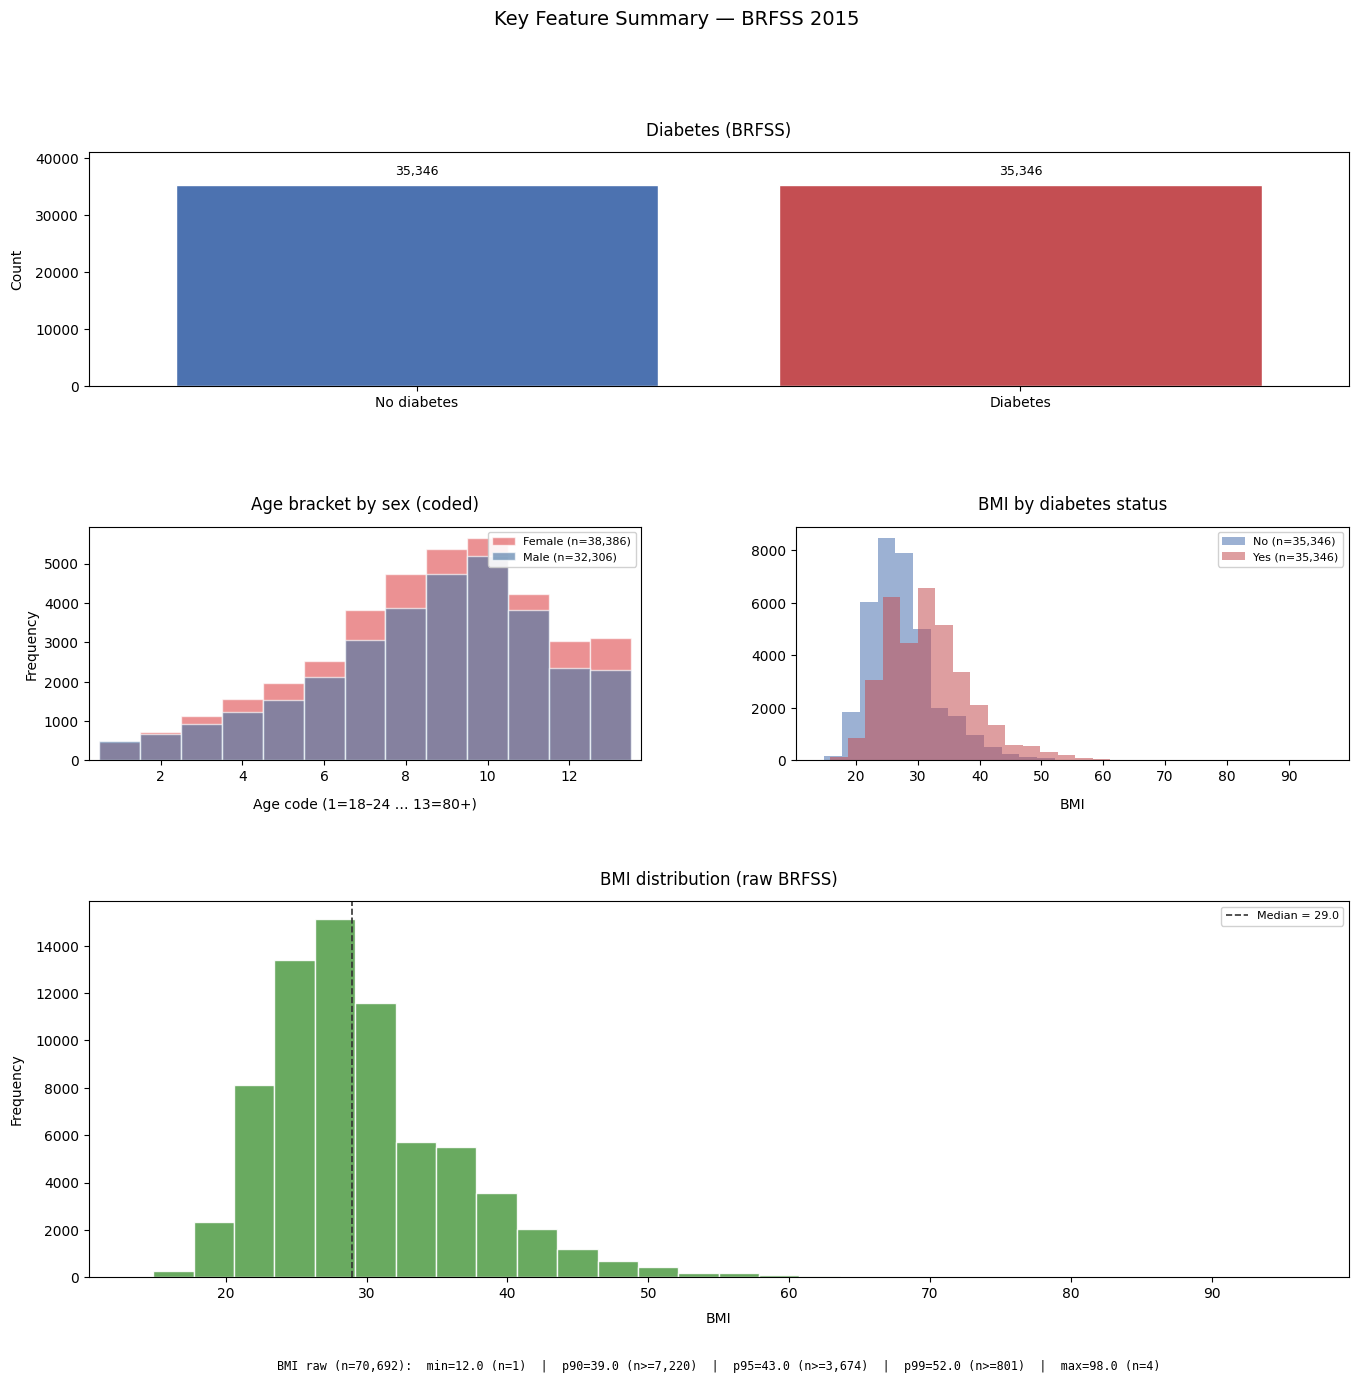

BMI raw (n=70,692):  min=12.0 (n=1)  |  p90=39.0 (n>=7,220)  |  p95=43.0 (n>=3,674)  |  p99=52.0 (n>=801)  |  max=98.0 (n=4)


In [3]:
# Cell 06 · Summary plots code
import matplotlib.pyplot as plt

AGE_LABELS = {
    1: "18–24",
    2: "25–29",
    3: "30–34",
    4: "35–39",
    5: "40–44",
    6: "45–49",
    7: "50–54",
    8: "55–59",
    9: "60–64",
    10: "65–69",
    11: "70–74",
    12: "75–79",
    13: "80+",
}
def dm_bmi_distribution_footer(series) -> str:
    s = series.dropna().astype(float)
    n_total = len(s)
    bmin = float(s.min())
    bmax = float(s.max())
    p90 = float(s.quantile(0.90))
    p95 = float(s.quantile(0.95))
    p99 = float(s.quantile(0.99))
    n_min = int((s == bmin).sum())
    n_max = int((s == bmax).sum())
    n_ge_p90 = int((s >= p90).sum())
    n_ge_p95 = int((s >= p95).sum())
    n_ge_p99 = int((s >= p99).sum())
    return (
        f"BMI raw (n={n_total:,}):  "
        f"min={bmin:.1f} (n={n_min:,})  |  "
        f"p90={p90:.1f} (n>={n_ge_p90:,})  |  "
        f"p95={p95:.1f} (n>={n_ge_p95:,})  |  "
        f"p99={p99:.1f} (n>={n_ge_p99:,})  |  "
        f"max={bmax:.1f} (n={n_max:,})"
    )


def dm_bar_count_labels(ax, bars, padding: float = 5) -> None:
    heights = [bar.get_height() for bar in bars]
    if not heights:
        return
    ax.bar_label(
        bars,
        labels=[f"{int(h):,}" for h in heights],
        padding=padding,
        fontsize=9,
    )
    ax.set_ylim(0, max(heights) * 1.16)


fig = plt.figure(figsize=(14, 15.0))
grid = fig.add_gridspec(3, 2, height_ratios=[0.92, 0.92, 1.48], hspace=0.50, wspace=0.28)

ax_outcome = fig.add_subplot(grid[0, :])
outcome_counts = df_raw["diabetes_binary"].value_counts().sort_index()
bars = ax_outcome.bar(
    ["No diabetes", "Diabetes"],
    [outcome_counts.get(0, 0), outcome_counts.get(1, 0)],
    color=["#4C72B0", "#C44E52"],
    edgecolor="white",
)
ax_outcome.set_title("Diabetes (BRFSS)", pad=12)
ax_outcome.set_ylabel("Count", labelpad=8)
ax_outcome.margins(x=0.08)
dm_bar_count_labels(ax_outcome, bars)

sex_colors = {0: "#E15759", 1: "#4E79A7"}
sex_labels = {0: "Female", 1: "Male"}

ax_age = fig.add_subplot(grid[1, 0])
for sex_code, label in sex_labels.items():
    ages = df_raw.loc[df_raw["sex"] == sex_code, "age"].dropna()
    ax_age.hist(
        ages,
        bins=np.arange(0.5, 14.5, 1),
        alpha=0.65,
        label=f"{label} (n={len(ages):,})",
        color=sex_colors[sex_code],
        edgecolor="white",
    )
ax_age.set_title("Age bracket by sex (coded)", pad=12)
ax_age.set_xlabel("Age code (1=18–24 … 13=80+)", labelpad=10)
ax_age.set_ylabel("Frequency")
ax_age.legend(fontsize=8, loc="upper right", framealpha=0.9)
ax_age.margins(x=0.02)

ax_bmi = fig.add_subplot(grid[1, 1])
for outcome, name, color in (
    (0, "No", "#4C72B0"),
    (1, "Yes", "#C44E52"),
):
    subset = df_raw.loc[df_raw["diabetes_binary"] == outcome, "bmi"]
    ax_bmi.hist(subset, bins=30, alpha=0.55, label=f"{name} (n={len(subset):,})", color=color)
ax_bmi.set_title("BMI by diabetes status", pad=12)
ax_bmi.set_xlabel("BMI", labelpad=10)
ax_bmi.legend(loc="upper right", fontsize=8, framealpha=0.9)
ax_bmi.margins(x=0.02)

ax_bmi_all = fig.add_subplot(grid[2, :])
bmi_vals = df_raw["bmi"].dropna()
ax_bmi_all.hist(
    bmi_vals,
    bins=30,
    color="#59A14F",
    edgecolor="white",
    alpha=0.9,
)
median_bmi = float(bmi_vals.median())
ax_bmi_all.axvline(
    median_bmi,
    color="#333333",
    linestyle="--",
    linewidth=1.2,
    label=f"Median = {median_bmi:.1f}",
)
ax_bmi_all.set_title("BMI distribution (raw BRFSS)", pad=12)
ax_bmi_all.set_xlabel("BMI", labelpad=8)
ax_bmi_all.set_ylabel("Frequency", labelpad=8)
ax_bmi_all.tick_params(axis="x", pad=3)
ax_bmi_all.margins(x=0.02)
ax_bmi_all.legend(loc="upper right", fontsize=8, framealpha=0.9)

fig.suptitle("Key Feature Summary — BRFSS 2015", fontsize=14, y=0.995)
fig.subplots_adjust(top=0.90, hspace=0.78, wspace=0.30, bottom=0.15, left=0.08, right=0.98)

bmi_footer = dm_bmi_distribution_footer(bmi_vals)
ax_bmi_all.text(
    0.5,
    -0.22,
    bmi_footer,
    transform=ax_bmi_all.transAxes,
    ha="center",
    va="top",
    fontsize=8.5,
    family="monospace",
    clip_on=False,
)
plt.show()
print(bmi_footer)


**Cell 07 · Modeling target overview**

## Modeling target (binary)

**`diabetes_outcome`** is the binary label for modeling (0 = no diabetes, 1 = diabetes). The source column **`diabetes_binary`** is dropped from predictors to avoid leakage; **`heart_disease_or_attack`** and other BRFSS fields remain as features.


In [4]:
# Cell 08 · Modeling target code
from IPython.display import display

DIABETES_OUTCOME_COL = "diabetes_outcome"

predictor_cols = [c for c in df.columns if c != "diabetes_binary"]
df_model = df[predictor_cols].copy()
df_model[DIABETES_OUTCOME_COL] = df_raw["diabetes_binary"].astype(int)

outcome_reference = pd.DataFrame(
    {
        "class_id": [0, 1],
        "label": ["No diabetes", "Diabetes"],
    }
)

print(f"Modeling table: {df_model.shape[0]:,} rows × {df_model.shape[1]} columns")
print(f"Outcome column: {DIABETES_OUTCOME_COL}")
display(outcome_reference)
print("\nClass counts:")
print(df_model[DIABETES_OUTCOME_COL].value_counts().sort_index().to_string())
df_model.head()


Modeling table: 70,692 rows × 22 columns
Outcome column: diabetes_outcome


,class_id,label
0,0,No diabetes
1,1,Diabetes



Class counts:
diabetes_outcome
0    35346
1    35346


,high_bp,high_chol,chol_check,bmi,smoker,stroke,heart_disease_or_attack,phys_activity,fruits,veggies,...,no_docbc_cost,gen_hlth,ment_hlth,phys_hlth,diff_walk,sex,age,education,income,diabetes_outcome
0,1.0000,0.0000,1.0000,26.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,...,0.0000,3.0000,5.0000,30.0000,0.0000,1.0000,4.0000,6.0000,8.0000,0
1,1.0000,1.0000,1.0000,26.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,...,0.0000,3.0000,0.0000,0.0000,0.0000,1.0000,12.0000,6.0000,8.0000,0
2,0.0000,0.0000,1.0000,26.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,1.0000,0.0000,10.0000,0.0000,1.0000,13.0000,6.0000,8.0000,0
3,1.0000,1.0000,1.0000,28.0000,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,3.0000,0.0000,3.0000,0.0000,1.0000,11.0000,6.0000,8.0000,0
4,0.0000,0.0000,1.0000,29.0000,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,2.0000,0.0000,0.0000,0.0000,0.0000,8.0000,5.0000,8.0000,0


**Cell 09 · Scale predictors overview**

### Transform and scale continuous predictors

**`bmi`** is right-skewed (typical skew > 1). **`StandardScaler` alone does not remove skew** — it only centers and rescales. For logistic regression we want a smoother, more symmetric predictor so the **log-odds are approximately linear in BMI** and extreme values carry less leverage.

Pipeline for ratio columns (currently **`bmi`** only): **`PowerTransformer`** (Yeo–Johnson) → **`StandardScaler`**. Ordinal BRFSS codes and binary indicators stay on their original scales. Output: **`df_model_scaled`** for downstream classifiers.


In [5]:
# Cell 10 · Scale & modeling table code
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler

if "df_model" not in globals():
    raise NameError("Run Cell 08 (modeling target) first.")
if "measurement_levels" not in globals():
    raise NameError("Run Cell 04 (unified summary) first.")

CONTINUOUS_LEVELS = {"ratio", "interval"}

MODELING_PREDICTOR_COLS = [c for c in df_model.columns if c != DIABETES_OUTCOME_COL]
df_model_modeling = df_model[MODELING_PREDICTOR_COLS + [DIABETES_OUTCOME_COL]].copy()

CONTINUOUS_PREDICTOR_COLS = [
    c
    for c in MODELING_PREDICTOR_COLS
    if measurement_levels.get(c) in CONTINUOUS_LEVELS
]
ORDINAL_OR_NOMINAL_COLS = [
    c for c in MODELING_PREDICTOR_COLS if c not in CONTINUOUS_PREDICTOR_COLS
]

df_model_scaled = df_model_modeling.copy()
dm_continuous_preprocessors: dict[str, Pipeline] = {}
for col in CONTINUOUS_PREDICTOR_COLS:
    pipe = Pipeline(
        [
            ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
            ("standardize", StandardScaler()),
        ]
    )
    values = df_model_modeling[[col]].astype(float)
    df_model_scaled[col] = pipe.fit_transform(values).ravel()
    dm_continuous_preprocessors[col] = pipe

print(
    f"Modeling table: {df_model_modeling.shape[0]:,} rows × {df_model_modeling.shape[1]} columns "
    f"({len(MODELING_PREDICTOR_COLS)} predictors + {DIABETES_OUTCOME_COL})"
)
print(
    f"Continuous columns (Yeo–Johnson + StandardScaler) ({len(CONTINUOUS_PREDICTOR_COLS)}): "
    f"{CONTINUOUS_PREDICTOR_COLS}"
)
print(f"Unscaled predictors ({len(ORDINAL_OR_NOMINAL_COLS)}): {ORDINAL_OR_NOMINAL_COLS}")


def _count_iqr_outliers(series: pd.Series) -> int:
    if "iqr_outlier_count" in globals():
        return int(iqr_outlier_count(series))
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((series < lower) | (series > upper)).sum())


def _final_modeling_feature_summary(frame: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    rows: list[dict] = []
    for col in features:
        s = pd.to_numeric(frame[col], errors="coerce")
        vals = s.dropna()
        level = measurement_levels.get(col, "unknown")
        distribution_stats = level in {"interval", "ratio"}
        rows.append(
            {
                "feature": col,
                "measurement_level": level,
                "transformed_scaled": col in CONTINUOUS_PREDICTOR_COLS,
                "count": int(vals.count()),
                "mean": round(float(vals.mean()), 4) if len(vals) else None,
                "std": round(float(vals.std(ddof=0)), 4) if len(vals) else None,
                "min": round(float(vals.min()), 4) if len(vals) else None,
                "max": round(float(vals.max()), 4) if len(vals) else None,
                "skew": round(float(vals.skew()), 3) if len(vals) >= 3 else None,
                "iqr_outliers": _count_iqr_outliers(vals)
                if distribution_stats and len(vals) >= 4
                else None,
            }
        )
    return pd.DataFrame(rows).set_index("feature")


print("\n=== Final modeling matrix — feature summary ===")
display(_final_modeling_feature_summary(df_model_scaled, MODELING_PREDICTOR_COLS))

print("\n=== Final modeling matrix — first rows ===")
display(df_model_scaled.head(10))

export_path = COMPILED_DIR / "brfss_diabetes_modeling_table_5050split.parquet"
try:
    df_model_scaled.to_parquet(export_path, index=False)
    print(f"\nSaved: {export_path}")
except Exception as exc:
    csv_path = COMPILED_DIR / "brfss_diabetes_modeling_table_5050split.csv"
    df_model_scaled.to_csv(csv_path, index=False)
    print(f"\nParquet unavailable ({exc}); saved CSV: {csv_path}")


Modeling table: 70,692 rows × 22 columns (21 predictors + diabetes_outcome)
Continuous columns (Yeo–Johnson + StandardScaler) (1): ['bmi']
Unscaled predictors (20): ['high_bp', 'high_chol', 'chol_check', 'smoker', 'stroke', 'heart_disease_or_attack', 'phys_activity', 'fruits', 'veggies', 'hvy_alcohol_consump', 'any_healthcare', 'no_docbc_cost', 'gen_hlth', 'ment_hlth', 'phys_hlth', 'diff_walk', 'sex', 'age', 'education', 'income']

=== Final modeling matrix — feature summary ===


,measurement_level,transformed_scaled,count,mean,std,min,max,skew,iqr_outliers
feature,,,,,,,,,
high_bp,nominal (binary),False,70692,0.5635,0.4960,0.0000,1.0000,-0.2560,NaN
high_chol,nominal (binary),False,70692,0.5257,0.4993,0.0000,1.0000,-0.1030,NaN
chol_check,nominal (binary),False,70692,0.9753,0.1553,0.0000,1.0000,-6.1190,NaN
bmi,ratio,True,70692,-0.0000,1.0000,-5.5456,3.8983,-0.0150,645.0000
smoker,nominal (binary),False,70692,0.4753,0.4994,0.0000,1.0000,0.0990,NaN
stroke,nominal (binary),False,70692,0.0622,0.2415,0.0000,1.0000,3.6260,NaN
heart_disease_or_attack,nominal (binary),False,70692,0.1478,0.3549,0.0000,1.0000,1.9850,NaN
phys_activity,nominal (binary),False,70692,0.7030,0.4569,0.0000,1.0000,-0.8890,NaN
fruits,nominal (binary),False,70692,0.6118,0.4873,0.0000,1.0000,-0.4590,NaN



=== Final modeling matrix — first rows ===


,high_bp,high_chol,chol_check,bmi,smoker,stroke,heart_disease_or_attack,phys_activity,fruits,veggies,...,no_docbc_cost,gen_hlth,ment_hlth,phys_hlth,diff_walk,sex,age,education,income,diabetes_outcome
0,1.0000,0.0000,1.0000,-0.4755,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,...,0.0000,3.0000,5.0000,30.0000,0.0000,1.0000,4.0000,6.0000,8.0000,0
1,1.0000,1.0000,1.0000,-0.4755,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,...,0.0000,3.0000,0.0000,0.0000,0.0000,1.0000,12.0000,6.0000,8.0000,0
2,0.0000,0.0000,1.0000,-0.4755,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,1.0000,0.0000,10.0000,0.0000,1.0000,13.0000,6.0000,8.0000,0
3,1.0000,1.0000,1.0000,-0.1112,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,3.0000,0.0000,3.0000,0.0000,1.0000,11.0000,6.0000,8.0000,0
4,0.0000,0.0000,1.0000,0.0551,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,2.0000,0.0000,0.0000,0.0000,0.0000,8.0000,5.0000,8.0000,0
5,0.0000,0.0000,1.0000,-2.5751,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,2.0000,7.0000,0.0000,0.0000,0.0000,1.0000,4.0000,7.0000,0
6,0.0000,1.0000,1.0000,-0.4755,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,13.0000,5.0000,6.0000,0
7,0.0000,0.0000,1.0000,0.3603,1.0000,0.0000,0.0000,0.0000,1.0000,1.0000,...,0.0000,4.0000,0.0000,0.0000,0.0000,1.0000,6.0000,4.0000,3.0000,0
8,0.0000,0.0000,1.0000,0.5007,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,3.0000,0.0000,0.0000,0.0000,0.0000,3.0000,6.0000,8.0000,0
9,0.0000,0.0000,1.0000,-0.2877,1.0000,0.0000,0.0000,0.0000,1.0000,1.0000,...,0.0000,3.0000,0.0000,6.0000,0.0000,1.0000,6.0000,4.0000,4.0000,0



Saved: compiled\brfss_diabetes_modeling_table_5050split.parquet


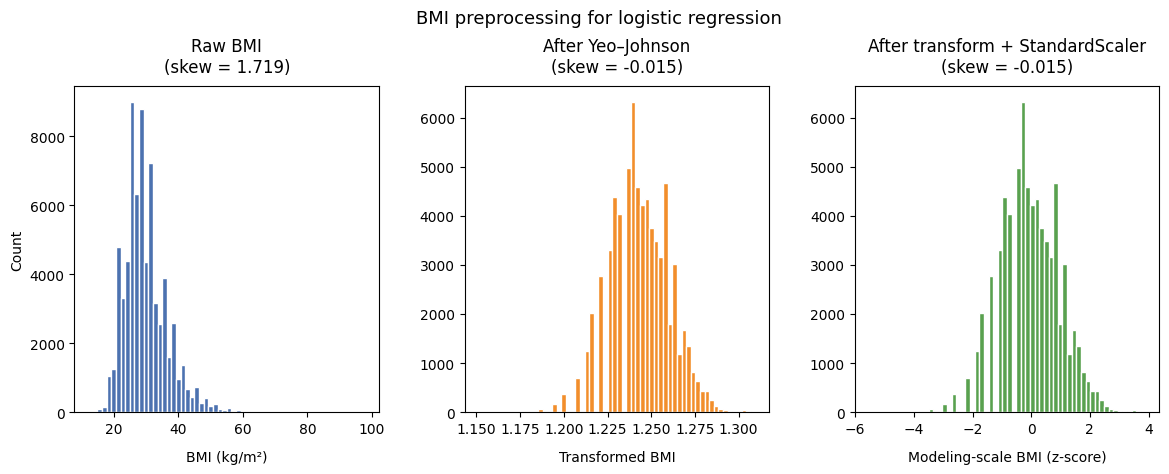

BMI skew: raw 1.7192 → Yeo–Johnson -0.0153 → modeling matrix -0.0153


In [6]:
# Cell 11 · BMI skew — Yeo–Johnson transform then StandardScaler
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import PowerTransformer

if "df_model_modeling" not in globals() or "df_model_scaled" not in globals():
    raise NameError("Run Cell 10 (scale & modeling table) first.")

bmi_raw = df_model_modeling["bmi"].astype(float)
bmi_yj = PowerTransformer(method="yeo-johnson", standardize=False).fit_transform(
    bmi_raw.values.reshape(-1, 1)
).ravel()
bmi_model = df_model_scaled["bmi"].astype(float)

skew_raw = float(stats.skew(bmi_raw, bias=False))
skew_yj = float(stats.skew(bmi_yj, bias=False))
skew_model = float(stats.skew(bmi_model, bias=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
axes[0].hist(bmi_raw, bins=60, color="#4C72B0", edgecolor="white")
axes[0].set_title(f"Raw BMI\n(skew = {skew_raw:.3f})", pad=10)
axes[0].set_xlabel("BMI (kg/m²)", labelpad=10)
axes[0].set_ylabel("Count")

axes[1].hist(bmi_yj, bins=60, color="#F28E2B", edgecolor="white")
axes[1].set_title(f"After Yeo–Johnson\n(skew = {skew_yj:.3f})", pad=10)
axes[1].set_xlabel("Transformed BMI", labelpad=10)

axes[2].hist(bmi_model, bins=60, color="#59A14F", edgecolor="white")
axes[2].set_title(f"After transform + StandardScaler\n(skew = {skew_model:.3f})", pad=10)
axes[2].set_xlabel("Modeling-scale BMI (z-score)", labelpad=10)

fig.suptitle("BMI preprocessing for logistic regression", fontsize=13, y=0.98)
fig.subplots_adjust(top=0.82, wspace=0.28, bottom=0.14)
plt.show()

print(
    f"BMI skew: raw {skew_raw:.4f} → Yeo–Johnson {skew_yj:.4f} → "
    f"modeling matrix {skew_model:.4f}"
)


**Cell 12 · Boruta overview**

## Boruta-style feature importance (exploratory)

Random forest on **`diabetes_outcome`** with **shadow** features (column-wise permutations). Each real feature is compared to the max shadow importance each iteration:

- **confirmed** — beat max shadow in ≥ 60% of iterations  
- **rejected** — beat max shadow in ≤ 30%  
- **tentative** — in between  

**No features are dropped** from **`df_model_scaled`** for modeling in later cells; this is for ranking and interpretation only. On the full BRFSS file we use a **stratified subsample** for runtime (`BORUTA_MAX_ROWS`).


In [7]:
# Cell 13 · Boruta RF — table & rankings
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

if "df_model_scaled" not in globals() or "MODELING_PREDICTOR_COLS" not in globals():
    raise NameError("Run Cell 10 first.")

BORUTA_TARGET = DIABETES_OUTCOME_COL
BORUTA_FULL_RUN = False
if BORUTA_FULL_RUN:
    BORUTA_N_ITER, BORUTA_N_ESTIMATORS = 50, 500
else:
    BORUTA_N_ITER, BORUTA_N_ESTIMATORS = 15, 200
BORUTA_N_JOBS = 1
BORUTA_RANDOM_STATE = 42 if "DM_MODEL_RANDOM_STATE" not in globals() else DM_MODEL_RANDOM_STATE
BORUTA_MAX_ROWS = 20000

X_full = df_model_scaled[MODELING_PREDICTOR_COLS].astype(float)
y_full = df_model_scaled[BORUTA_TARGET].astype(int)
if len(y_full) > BORUTA_MAX_ROWS:
    X_boruta, _, y_boruta, _ = train_test_split(
        X_full,
        y_full,
        train_size=BORUTA_MAX_ROWS,
        stratify=y_full,
        random_state=BORUTA_RANDOM_STATE,
    )
    print(
        f"Boruta subsample: {len(y_boruta):,} rows (stratified from {len(y_full):,})"
    )
else:
    X_boruta, y_boruta = X_full, y_full

feature_names = list(X_boruta.columns)
hits = pd.Series(0, index=feature_names, dtype=int)
importance_history: dict[str, list[float]] = {f: [] for f in feature_names}
shadow_min_hist: list[float] = []
shadow_mean_hist: list[float] = []
shadow_max_hist: list[float] = []

boruta_t0 = time.perf_counter()
print(
    f"Starting Boruta: {BORUTA_N_ITER} iterations × {BORUTA_N_ESTIMATORS} trees "
    f"({len(y_boruta):,} rows, {len(feature_names)} features)...",
    flush=True,
)

for seed in range(BORUTA_N_ITER):
    rng = np.random.default_rng(seed)
    X_shadow = X_boruta.copy()
    for col in X_shadow.columns:
        X_shadow[col] = rng.permutation(X_shadow[col].values)

    shadow_names = [f"{c}__shadow" for c in feature_names]
    X_aug = pd.concat(
        [X_boruta.reset_index(drop=True), X_shadow.reset_index(drop=True)],
        axis=1,
    )
    X_aug.columns = feature_names + shadow_names

    rf = RandomForestClassifier(
        n_estimators=BORUTA_N_ESTIMATORS,
        class_weight="balanced_subsample",
        random_state=seed,
        n_jobs=BORUTA_N_JOBS,
    )
    rf.fit(X_aug.to_numpy(), y_boruta.to_numpy())
    imp = pd.Series(rf.feature_importances_, index=X_aug.columns)
    shadow_imps = imp[shadow_names]
    shadow_min_hist.append(float(shadow_imps.min()))
    shadow_mean_hist.append(float(shadow_imps.mean()))
    shadow_max_hist.append(float(shadow_imps.max()))
    shadow_max = float(shadow_imps.max())
    hits += (imp[feature_names] > shadow_max).astype(int)
    for feature in feature_names:
        importance_history[feature].append(float(imp[feature]))
    if (seed + 1) % max(1, BORUTA_N_ITER // 5) == 0 or seed == 0:
        print(
            f"  iteration {seed + 1}/{BORUTA_N_ITER} "
            f"({time.perf_counter() - boruta_t0:.0f}s elapsed)",
            flush=True,
        )

print(f"Boruta loop finished in {time.perf_counter() - boruta_t0:.1f}s", flush=True)


def boruta_decision(hit_rate: float) -> str:
    if hit_rate >= 0.6:
        return "confirmed"
    if hit_rate <= 0.3:
        return "rejected"
    return "tentative"


boruta_importance = (
    pd.DataFrame(
        {
            "hits": hits,
            "hit_rate": hits / BORUTA_N_ITER,
            "min_importance": [min(importance_history[f]) for f in feature_names],
            "max_importance": [max(importance_history[f]) for f in feature_names],
            "mean_importance": [
                float(np.mean(importance_history[f])) for f in feature_names
            ],
        },
        index=feature_names,
    )
    .assign(decision=lambda df: df["hit_rate"].map(boruta_decision))
    .sort_values(["hit_rate", "mean_importance"], ascending=False)
)

n_boruta_features = len(feature_names)
n_rf_inputs = n_boruta_features * 2
chance_importance_pct = 100 / n_rf_inputs

print(
    f"Boruta-style RF: {BORUTA_N_ITER} iterations, "
    f"target={BORUTA_TARGET}, n={len(y_boruta):,} rows, p={n_boruta_features} features"
)
print(
    f"RF importances sum to 1 across {n_rf_inputs} columns (real + shadow); "
    f"~{chance_importance_pct:.2f}% is the per-column baseline.\n"
)

boruta_display = boruta_importance.assign(
    rank=lambda df: range(1, len(df) + 1),
    min_importance_pct=lambda df: df["min_importance"] * 100,
    max_importance_pct=lambda df: df["max_importance"] * 100,
    mean_importance_pct=lambda df: df["mean_importance"] * 100,
)[
    [
        "rank",
        "hits",
        "hit_rate",
        "mean_importance_pct",
        "max_importance_pct",
        "decision",
    ]
]

print("Decision counts:")
print(boruta_importance["decision"].value_counts().to_string())
display(boruta_display)

print(
    "\nBoruta is exploratory only — Cells 16+ keep all predictors in "
    "`MODELING_PREDICTOR_COLS` (no feature drop)."
)


Boruta subsample: 20,000 rows (stratified from 70,692)
Starting Boruta: 15 iterations × 200 trees (20,000 rows, 21 features)...
  iteration 1/15 (5s elapsed)
  iteration 3/15 (17s elapsed)
  iteration 6/15 (34s elapsed)
  iteration 9/15 (49s elapsed)
  iteration 12/15 (63s elapsed)
  iteration 15/15 (81s elapsed)
Boruta loop finished in 81.4s
Boruta-style RF: 15 iterations, target=diabetes_outcome, n=20,000 rows, p=21 features
RF importances sum to 1 across 42 columns (real + shadow); ~2.38% is the per-column baseline.

Decision counts:
decision
rejected     17
confirmed     4


,rank,hits,hit_rate,mean_importance_pct,max_importance_pct,decision
bmi,1,15,1.0000,9.6807,9.8792,confirmed
gen_hlth,2,15,1.0000,8.5826,8.7971,confirmed
age,3,15,1.0000,7.1022,7.3020,confirmed
high_bp,4,15,1.0000,6.6459,7.1890,confirmed
income,5,0,0.0000,4.1174,4.1766,rejected
high_chol,6,0,0.0000,3.5024,3.7313,rejected
phys_hlth,7,0,0.0000,3.3311,3.4213,rejected
education,8,0,0.0000,2.6980,2.7435,rejected
ment_hlth,9,0,0.0000,2.3870,2.4184,rejected
diff_walk,10,0,0.0000,2.0576,2.2246,rejected



Boruta is exploratory only — Cells 16+ keep all predictors in `MODELING_PREDICTOR_COLS` (no feature drop).


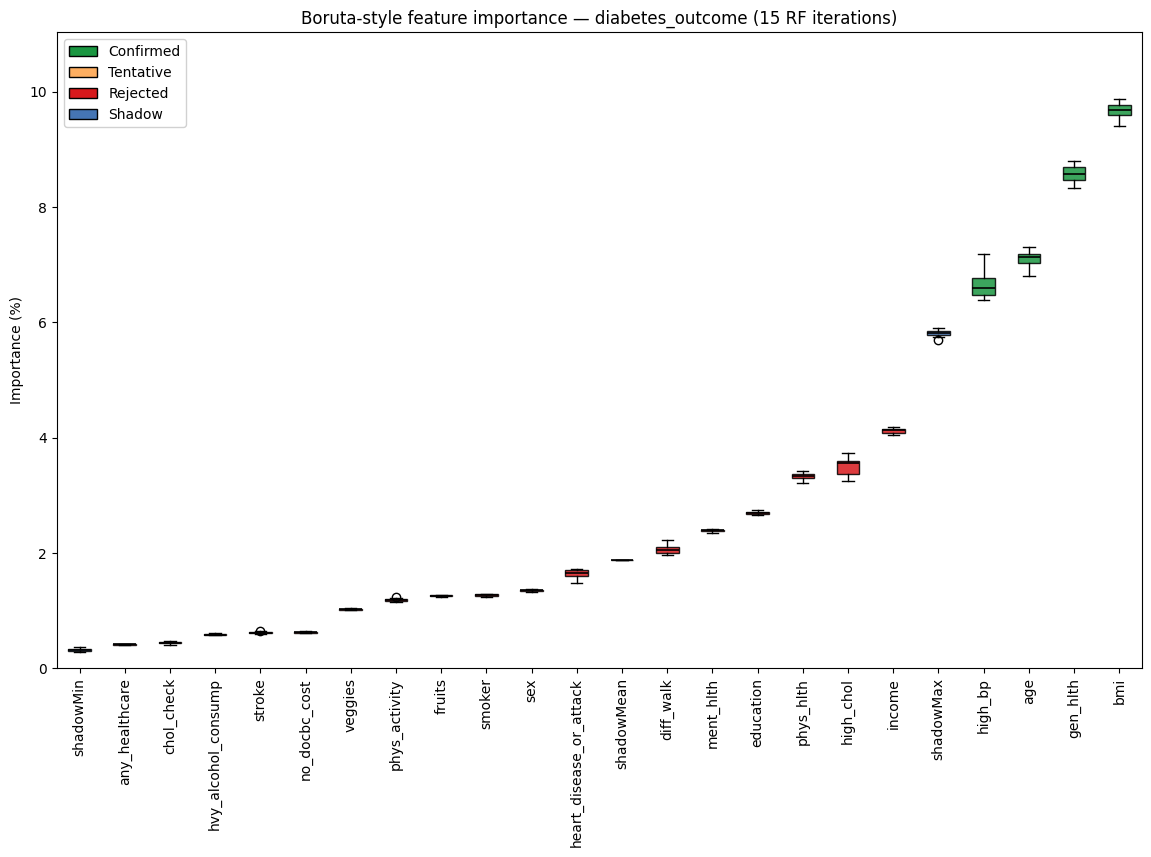

In [8]:
# Cell 14 · Boruta importance plot
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

if "boruta_importance" not in globals():
    raise RuntimeError("Run Cell 13 (Boruta RF) first.")

BORUTA_COLORS = {
    "confirmed": "#1a9641",
    "rejected": "#d7191c",
    "tentative": "#fdae61",
    "shadow": "#4575b4",
}

shadow_stats = {
    "shadowMin": shadow_min_hist,
    "shadowMean": shadow_mean_hist,
    "shadowMax": shadow_max_hist,
}

plot_items: list[tuple[str, list[float], str]] = []
for feature in feature_names:
    plot_items.append(
        (feature, importance_history[feature], boruta_importance.loc[feature, "decision"])
    )
for shadow_name, shadow_hist in shadow_stats.items():
    plot_items.append((shadow_name, shadow_hist, "shadow"))

plot_items.sort(key=lambda item: np.median(item[1]))
plot_labels = [item[0] for item in plot_items]
plot_data = [[v * 100 for v in item[1]] for item in plot_items]
plot_colors = [BORUTA_COLORS[item[2]] for item in plot_items]

fig, ax = plt.subplots(figsize=(max(14, len(plot_labels) * 0.35), 12))
boxplot = ax.boxplot(
    plot_data,
    tick_labels=plot_labels,
    vert=True,
    patch_artist=True,
    showfliers=True,
    medianprops={"color": "black", "linewidth": 1.2},
)
for patch, color in zip(boxplot["boxes"], plot_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

all_plot_vals = [v for series in plot_data for v in series]
y_min, y_max = min(all_plot_vals), max(all_plot_vals)
y_pad = max((y_max - y_min) * 0.12, 0.05)
ax.set_ylim(max(0.0, y_min - y_pad), y_max + y_pad)

ax.set_ylabel("Importance (%)")
ax.set_title(
    f"Boruta-style feature importance — {BORUTA_TARGET} ({BORUTA_N_ITER} RF iterations)"
)
legend_handles = [
    Patch(facecolor=BORUTA_COLORS["confirmed"], edgecolor="black", label="Confirmed"),
    Patch(facecolor=BORUTA_COLORS["tentative"], edgecolor="black", label="Tentative"),
    Patch(facecolor=BORUTA_COLORS["rejected"], edgecolor="black", label="Rejected"),
    Patch(facecolor=BORUTA_COLORS["shadow"], edgecolor="black", label="Shadow"),
]
ax.legend(handles=legend_handles, loc="upper left", framealpha=0.9)
ax.tick_params(axis="x", rotation=90)
fig.subplots_adjust(bottom=0.35)
plt.show()


**Cell 15 · Binary modeling overview**

Predict **`diabetes_outcome`** from **`df_model_scaled`** with **4-fold cross-validation** (stratified, shuffled, `random_state=42`). Each fold: train on 75%, test on 25%. We show metrics per fold, mean ± std, and **out-of-fold** ROC/confusion plots.

### Classes in this file (~50/50)

Cells **12–14** (Boruta) rank predictors for interpretation only; **`MODELING_PREDICTOR_COLS`** is unchanged below.

This subsample has about as many diabetes as non-diabetes rows. Cell 16 still computes **`class_weight = {0: w_no_diabetes, 1: w_diabetes}`** from each fold’s training set; the two weights are usually **equal**. Use **`DM_MINORITY_CLASS_WEIGHT_EMPHASIS > 1`** only if you want to deliberately overweight diabetes errors anyway.

### Balanced accuracy (what it means)

**Balanced accuracy** is the average of “how often we get **no diabetes** right” and “how often we get **diabetes** right,” treating both groups equally. Range 0–1; **0.5** is no better than guessing both labels blindly. On a 50/50 file it is often close to overall **accuracy**, but it is still the right metric when you compare back to the **14%** full cohort.

We also report **ROC AUC**, **precision** / **recall** / **F1** for diabetes at threshold 0.5.

Random forest uses **`max_samples=30_000`** per tree on the 5050 subsample.


Full sample: n=70,692, diabetes prevalence = 50.000%
Majority-class baseline (always predict no diabetes): accuracy = 50.000%
Example class_weight fed to the model (full sample, emphasis=1.0): no diabetes (0)=1.0000, diabetes (1)=1.0000 (diabetes mistakes weighted 1.00× more)
Logistic regression fold 1/4: AUC=0.8281, F1=0.7562, recall=0.7750, n_test=17,673
Logistic regression fold 2/4: AUC=0.8242, F1=0.7557, recall=0.7731, n_test=17,673
Logistic regression fold 3/4: AUC=0.8258, F1=0.7538, recall=0.7694, n_test=17,673
Logistic regression fold 4/4: AUC=0.8273, F1=0.7533, recall=0.7701, n_test=17,673

Logistic regression — 4-fold CV summary (mean ± std):


,mean,std
accuracy,0.7492,0.0010
balanced_accuracy,0.7492,0.0010
precision,0.7384,0.0006
recall,0.7719,0.0023
f1,0.7548,0.0012
roc_auc,0.8263,0.0015



=== Logistic regression — out-of-fold evaluation ===
Logistic regression (4-fold OOF) — ROC AUC: 0.8263


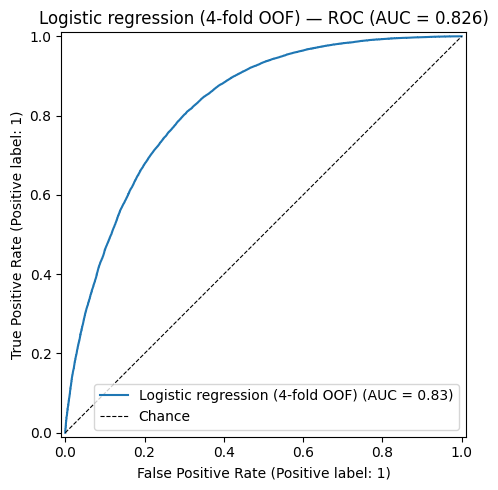

Confusion matrix (rows = true, columns = predicted):
[[25679  9667]
 [ 8063 27283]]


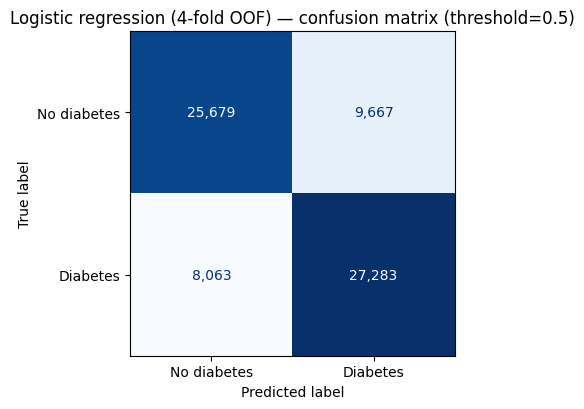

,value
accuracy,0.7492
balanced_accuracy,0.7492
precision,0.7384
recall,0.7719
f1,0.7548
roc_auc,0.8263


              precision    recall  f1-score   support

 No diabetes      0.761     0.727     0.743     35346
    Diabetes      0.738     0.772     0.755     35346

    accuracy                          0.749     70692
   macro avg      0.750     0.749     0.749     70692
weighted avg      0.750     0.749     0.749     70692


Coefficients — full-sample refit, target=diabetes_outcome, predictors=21
Intercept: -4.5859


,feature,coefficient,odds_ratio
2,chol_check,1.3344,3.7979
10,hvy_alcohol_consump,-0.7364,0.4788
0,high_bp,0.7114,2.0368
13,gen_hlth,0.5850,1.7950
1,high_chol,0.5732,1.7740
3,bmi,0.5602,1.7511
6,heart_disease_or_attack,0.2532,1.2881
17,sex,0.2413,1.2729
5,stroke,0.1767,1.1932
18,age,0.1546,1.1671


In [9]:
# Cell 16 · CV setup, class weights & logistic regression (4-fold)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold

if "df_model_scaled" not in globals():
    raise NameError("Run Cell 10 first.")

DM_MODEL_RANDOM_STATE = 42
DM_CV_FOLDS = 4
DM_MINORITY_CLASS_WEIGHT_EMPHASIS = 1.0
DIABETES_CLASS_NAMES = ["No diabetes", "Diabetes"]

frame = df_model_scaled.copy()
X = frame[MODELING_PREDICTOR_COLS].astype(float)
y = frame[DIABETES_OUTCOME_COL].astype(int)
if X.isna().any().any():
    raise ValueError("Predictors contain NaN.")

overall_prev = float(y.mean())
majority_baseline_acc = float((y == 0).mean())
print(f"Full sample: n={len(y):,}, diabetes prevalence = {overall_prev:.3%}")
print(
    f"Majority-class baseline (always predict no diabetes): "
    f"accuracy = {majority_baseline_acc:.3%}"
)


def dm_class_weight_dict(y_train, emphasis: float = 1.0) -> dict[int, float]:
    """Two fit-time weights {0, 1}; class 1 upweighted by rarity × emphasis."""
    y_arr = np.asarray(y_train, dtype=int)
    n = len(y_arr)
    n0 = int((y_arr == 0).sum())
    n1 = int((y_arr == 1).sum())
    if n0 == 0 or n1 == 0:
        raise ValueError("Both classes required in training fold.")
    return {
        0: n / (2.0 * n0),
        1: (n / (2.0 * n1)) * emphasis,
    }


ref_weights = dm_class_weight_dict(y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS)
print(
    f"Example class_weight fed to the model (full sample, emphasis={DM_MINORITY_CLASS_WEIGHT_EMPHASIS}): "
    f"no diabetes (0)={ref_weights[0]:.4f}, diabetes (1)={ref_weights[1]:.4f} "
    f"(diabetes mistakes weighted {ref_weights[1] / ref_weights[0]:.2f}× more)"
)

dm_skf = StratifiedKFold(
    n_splits=DM_CV_FOLDS,
    shuffle=True,
    random_state=DM_MODEL_RANDOM_STATE,
)


def _dm_fold_metrics(y_true, y_pred, y_prob) -> dict[str, float]:
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }


def _dm_binary_classification_eval(
    y_true,
    y_pred,
    y_prob_positive,
    class_names: list[str],
    model_title: str,
    cm_cmap: str = "Blues",
) -> pd.Series:
    """ROC/AUC, confusion matrix, and metrics (binary)."""
    test_auc = roc_auc_score(y_true, y_prob_positive)
    print(f"{model_title} — ROC AUC: {test_auc:.4f}")

    fig, ax = plt.subplots(figsize=(6, 5))
    RocCurveDisplay.from_predictions(
        y_true,
        y_prob_positive,
        ax=ax,
        name=model_title,
    )
    ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Chance")
    ax.set_title(f"{model_title} — ROC (AUC = {test_auc:.3f})")
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print("Confusion matrix (rows = true, columns = predicted):")
    print(cm)

    fig_cm, ax_cm = plt.subplots(figsize=(4.8, 4.2))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
        ax=ax_cm,
        cmap=cm_cmap,
        colorbar=False,
    )
    ax_cm.set_title(f"{model_title} — confusion matrix (threshold=0.5)")
    fig_cm.tight_layout()
    plt.show()

    metrics = pd.Series(_dm_fold_metrics(y_true, y_pred, y_prob_positive), name="value")
    display(metrics.to_frame())
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    return metrics


def dm_logistic_aic(
    model: LogisticRegression,
    X_df: pd.DataFrame,
    y_s: pd.Series,
    emphasis: float = 1.0,
) -> float:
    """AIC from class-weighted Bernoulli log-likelihood (full-sample refit)."""
    cw = dm_class_weight_dict(y_s, emphasis)
    y_arr = np.asarray(y_s, dtype=int)
    sw = np.where(y_arr == 1, cw[1], cw[0])
    p1 = np.clip(model.predict_proba(X_df)[:, 1], 1e-15, 1 - 1e-15)
    ll_i = y_arr * np.log(p1) + (1 - y_arr) * np.log(1 - p1)
    log_lik = float((sw * ll_i).sum())
    k = int(model.coef_.size + 1)
    return float(2 * k - 2 * log_lik)


def dm_run_cv(
    estimator,
    X_df: pd.DataFrame,
    y_s: pd.Series,
    cv: StratifiedKFold,
    emphasis: float,
    model_name: str,
) -> tuple[pd.DataFrame, pd.DataFrame, np.ndarray, np.ndarray]:
    oof_prob = np.zeros(len(y_s), dtype=float)
    oof_pred = np.zeros(len(y_s), dtype=int)
    fold_rows: list[dict] = []

    for fold, (train_idx, test_idx) in enumerate(cv.split(X_df, y_s), start=1):
        X_tr, X_te = X_df.iloc[train_idx], X_df.iloc[test_idx]
        y_tr, y_te = y_s.iloc[train_idx], y_s.iloc[test_idx]
        cw = dm_class_weight_dict(y_tr, emphasis)
        est = clone(estimator)
        est.set_params(class_weight=cw)
        est.fit(X_tr, y_tr)
        prob = est.predict_proba(X_te)[:, 1]
        pred = est.predict(X_te)
        oof_prob[test_idx] = prob
        oof_pred[test_idx] = pred
        m = _dm_fold_metrics(y_te, pred, prob)
        m["fold"] = fold
        m["n_train"] = len(y_tr)
        m["n_test"] = len(y_te)
        m["test_prevalence"] = float(y_te.mean())
        m["class_weight_1"] = cw[1]
        fold_rows.append(m)
        print(
            f"{model_name} fold {fold}/{DM_CV_FOLDS}: "
            f"AUC={m['roc_auc']:.4f}, F1={m['f1']:.4f}, "
            f"recall={m['recall']:.4f}, n_test={len(y_te):,}"
        )

    detail = pd.DataFrame(fold_rows).set_index("fold")
    metric_cols = [
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
    ]
    summary = pd.DataFrame(
        {
            "mean": detail[metric_cols].mean(),
            "std": detail[metric_cols].std(ddof=0),
        }
    )
    print(f"\n{model_name} — {DM_CV_FOLDS}-fold CV summary (mean ± std):")
    display(summary.round(4))
    return detail, summary, oof_pred, oof_prob


dm_logistic_base = LogisticRegression(max_iter=5000, solver="lbfgs")
(
    dm_logistic_cv_detail,
    dm_logistic_cv_summary,
    dm_logistic_oof_pred,
    dm_logistic_oof_prob,
) = dm_run_cv(
    dm_logistic_base,
    X,
    y,
    dm_skf,
    DM_MINORITY_CLASS_WEIGHT_EMPHASIS,
    "Logistic regression",
)

print("\n=== Logistic regression — out-of-fold evaluation ===")
dm_logistic_test_metrics = _dm_binary_classification_eval(
    y,
    dm_logistic_oof_pred,
    dm_logistic_oof_prob,
    DIABETES_CLASS_NAMES,
    f"Logistic regression ({DM_CV_FOLDS}-fold OOF)",
    cm_cmap="Blues",
)
dm_logistic_test_metrics.name = "logistic_regression"

dm_logistic_model = LogisticRegression(
    max_iter=5000,
    solver="lbfgs",
    class_weight=dm_class_weight_dict(y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS),
)
dm_logistic_model.fit(X, y)

dm_logistic_coef_table = pd.DataFrame(
    {
        "feature": MODELING_PREDICTOR_COLS,
        "coefficient": dm_logistic_model.coef_.ravel(),
    }
)
dm_logistic_coef_table["odds_ratio"] = np.exp(dm_logistic_coef_table["coefficient"])

print(
    f"\nCoefficients — full-sample refit, target={DIABETES_OUTCOME_COL}, "
    f"predictors={len(MODELING_PREDICTOR_COLS)}"
)
print(f"Intercept: {float(dm_logistic_model.intercept_[0]):.4f}")
display(
    dm_logistic_coef_table.sort_values(
        "coefficient", key=lambda s: s.abs(), ascending=False
    ).head(15)
)


Random forest fold 1/4: AUC=0.8167, F1=0.7532, recall=0.7878, n_test=17,673
Random forest fold 2/4: AUC=0.8181, F1=0.7549, recall=0.7878, n_test=17,673
Random forest fold 3/4: AUC=0.8158, F1=0.7507, recall=0.7809, n_test=17,673
Random forest fold 4/4: AUC=0.8192, F1=0.7539, recall=0.7850, n_test=17,673

Random forest — 4-fold CV summary (mean ± std):


,mean,std
accuracy,0.7426,0.0014
balanced_accuracy,0.7426,0.0014
precision,0.7234,0.0015
recall,0.7854,0.0028
f1,0.7531,0.0015
roc_auc,0.8174,0.0013



=== Random forest — out-of-fold evaluation ===
Random forest (4-fold OOF) — ROC AUC: 0.8174


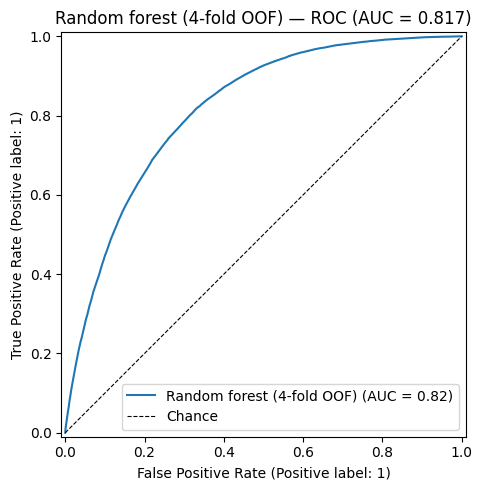

Confusion matrix (rows = true, columns = predicted):
[[24734 10612]
 [ 7586 27760]]


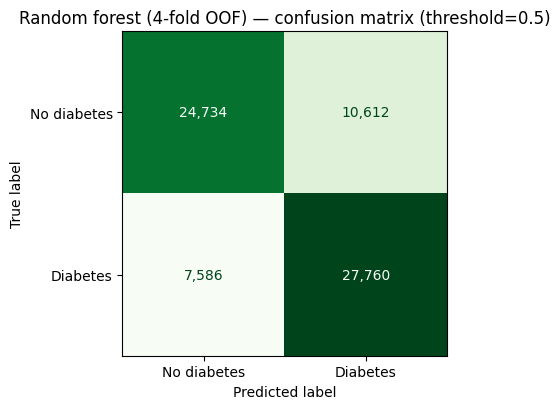

,value
accuracy,0.7426
balanced_accuracy,0.7426
precision,0.7234
recall,0.7854
f1,0.7531
roc_auc,0.8174


              precision    recall  f1-score   support

 No diabetes      0.765     0.700     0.731     35346
    Diabetes      0.723     0.785     0.753     35346

    accuracy                          0.743     70692
   macro avg      0.744     0.743     0.742     70692
weighted avg      0.744     0.743     0.742     70692


Feature importance — full-sample refit, trees=200, max_samples=30,000


,feature,importance
3,bmi,0.1683
18,age,0.1252
13,gen_hlth,0.1062
20,income,0.0834
0,high_bp,0.0799
15,phys_hlth,0.0678
19,education,0.0563
14,ment_hlth,0.0512
1,high_chol,0.0409
4,smoker,0.0287


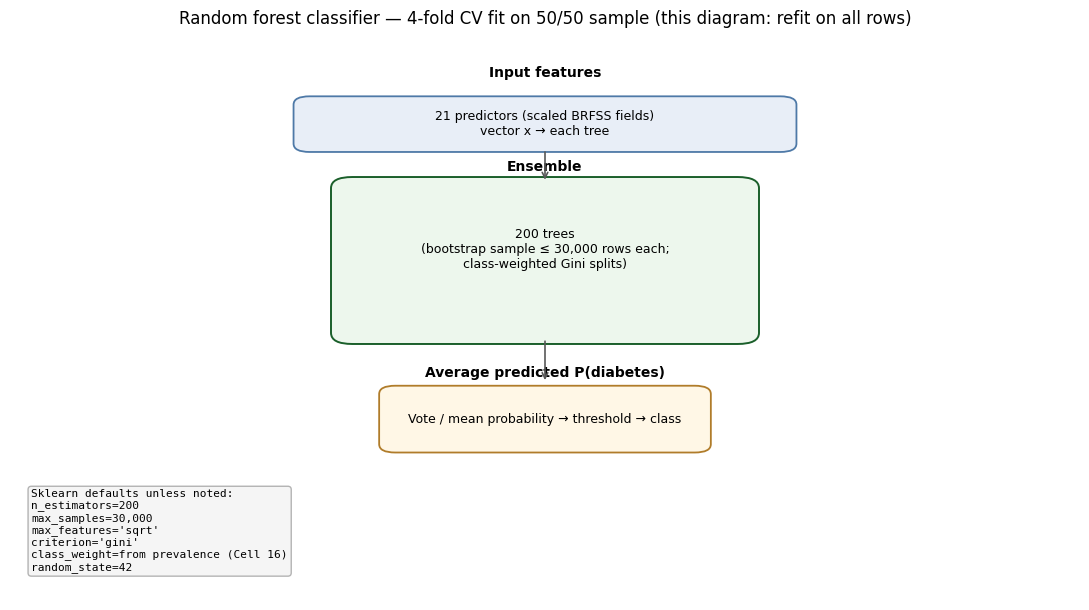

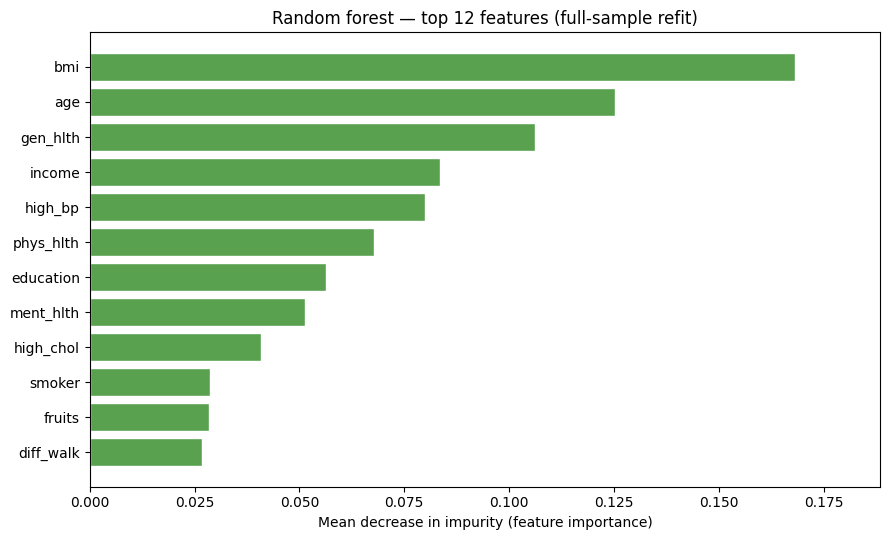

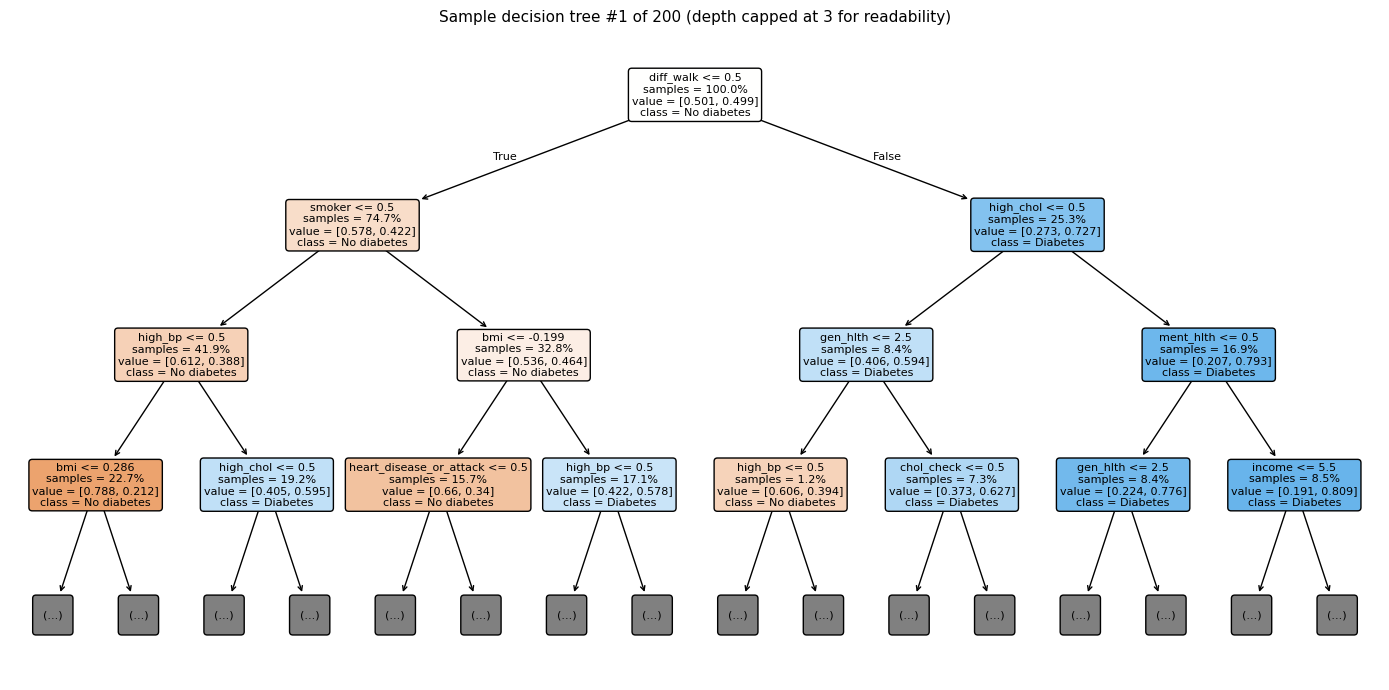

In [10]:
# Cell 17 · Random forest — 4-fold CV & feature importance
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier

if "X" not in globals() or "y" not in globals() or "dm_run_cv" not in globals():
    raise NameError("Run Cell 16 first.")

DM_RF_MAX_SAMPLES = 30_000

dm_rf_base = RandomForestClassifier(
    n_estimators=200,
    max_samples=DM_RF_MAX_SAMPLES,
    random_state=DM_MODEL_RANDOM_STATE,
    n_jobs=1,
)

(
    dm_rf_cv_detail,
    dm_rf_cv_summary,
    dm_rf_oof_pred,
    dm_rf_oof_prob,
) = dm_run_cv(
    dm_rf_base,
    X,
    y,
    dm_skf,
    DM_MINORITY_CLASS_WEIGHT_EMPHASIS,
    "Random forest",
)

print("\n=== Random forest — out-of-fold evaluation ===")
dm_rf_test_metrics = _dm_binary_classification_eval(
    y,
    dm_rf_oof_pred,
    dm_rf_oof_prob,
    DIABETES_CLASS_NAMES,
    f"Random forest ({DM_CV_FOLDS}-fold OOF)",
    cm_cmap="Greens",
)
dm_rf_test_metrics.name = "random_forest"

dm_rf_model = RandomForestClassifier(
    n_estimators=200,
    max_samples=DM_RF_MAX_SAMPLES,
    random_state=DM_MODEL_RANDOM_STATE,
    class_weight=dm_class_weight_dict(y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS),
    n_jobs=1,
)
dm_rf_model.fit(X, y)

dm_rf_importance = pd.DataFrame(
    {
        "feature": MODELING_PREDICTOR_COLS,
        "importance": dm_rf_model.feature_importances_,
    }
).sort_values("importance", ascending=False)

print(
    f"\nFeature importance — full-sample refit, trees=200, "
    f"max_samples={DM_RF_MAX_SAMPLES:,}"
)
display(dm_rf_importance.head(15))

# Diagram — Random forest structure, top feature importance, sample tree (interpretable scale)
from matplotlib.patches import FancyBboxPatch
from sklearn import tree as skl_tree

_rf = dm_rf_model
n_features = int(_rf.n_features_in_)

fig_rf, ax_rf = plt.subplots(figsize=(11, 6.2))
ax_rf.set_xlim(0, 1)
ax_rf.set_ylim(0, 1)
ax_rf.axis("off")
ax_rf.set_title(
    f"Random forest classifier — {DM_CV_FOLDS}-fold CV fit on 50/50 sample (this diagram: refit on all rows)",
    fontsize=12,
    pad=14,
)

ax_rf.text(0.5, 0.94, "Input features", ha="center", fontsize=10, fontweight="bold")
ax_rf.add_patch(
    FancyBboxPatch(
        (0.28, 0.82),
        0.44,
        0.07,
        boxstyle="round,pad=0.015",
        linewidth=1.3,
        edgecolor="#4E79A7",
        facecolor="#e8eef7",
    )
)
ax_rf.text(
    0.5,
    0.855,
    f"{n_features} predictors (scaled BRFSS fields)\nvector x → each tree",
    ha="center",
    va="center",
    fontsize=9,
)

forest_x, forest_y, forest_w, forest_h = 0.32, 0.48, 0.36, 0.26
ax_rf.add_patch(
    FancyBboxPatch(
        (forest_x, forest_y),
        forest_w,
        forest_h,
        boxstyle="round,pad=0.02",
        linewidth=1.4,
        edgecolor="#1a5f2a",
        facecolor="#edf7ed",
    )
)
ax_rf.text(0.5, forest_y + forest_h + 0.03, "Ensemble", ha="center", fontsize=10, fontweight="bold")
ax_rf.text(
    0.5,
    forest_y + forest_h / 2 + 0.02,
    f"{int(_rf.n_estimators)} trees\n(bootstrap sample ≤ {DM_RF_MAX_SAMPLES:,} rows each;\nclass-weighted Gini splits)",
    ha="center",
    va="center",
    fontsize=9,
)

ax_rf.annotate(
    "",
    xy=(0.5, forest_y + forest_h + 0.01),
    xytext=(0.5, 0.81),
    arrowprops=dict(arrowstyle="->", color="0.35", lw=1.2),
)

ax_rf.text(0.5, 0.40, "Average predicted P(diabetes)", ha="center", fontsize=10, fontweight="bold")
ax_rf.add_patch(
    FancyBboxPatch(
        (0.36, 0.28),
        0.28,
        0.09,
        boxstyle="round,pad=0.015",
        linewidth=1.3,
        edgecolor="#b07c2a",
        facecolor="#fff7e6",
    )
)
ax_rf.text(
    0.5,
    0.325,
    "Vote / mean probability → threshold → class",
    ha="center",
    va="center",
    fontsize=9,
)
ax_rf.annotate(
    "",
    xy=(0.5, 0.39),
    xytext=(0.5, forest_y - 0.01),
    arrowprops=dict(arrowstyle="->", color="0.35", lw=1.2),
)

param_lines = [
    f"n_estimators={_rf.n_estimators}",
    f"max_samples={DM_RF_MAX_SAMPLES:,}",
    f"max_features={_rf.max_features!r}",
    f"criterion={_rf.criterion!r}",
    f"class_weight=from prevalence (Cell 16)",
    f"random_state={_rf.random_state}",
]
ax_rf.text(
    0.02,
    0.20,
    "Sklearn defaults unless noted:\n" + "\n".join(param_lines),
    ha="left",
    va="top",
    fontsize=8,
    family="monospace",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="#f5f5f5", edgecolor="0.7"),
)
fig_rf.tight_layout()
plt.show()

_plot_top = dm_rf_importance.head(12).iloc[::-1]
fig_imp, ax_imp = plt.subplots(figsize=(9, 5.5))
ax_imp.barh(_plot_top["feature"], _plot_top["importance"], color="#59A14F", edgecolor="white")
ax_imp.set_xlabel("Mean decrease in impurity (feature importance)")
ax_imp.set_title("Random forest — top 12 features (full-sample refit)")
ax_imp.set_xlim(0, max(_plot_top["importance"].max() * 1.12, 1e-6))
fig_imp.tight_layout()
plt.show()

_tree_idx = 0  # first tree in the forest (illustrative)
fig_tree, ax_tree = plt.subplots(figsize=(14, 7))
skl_tree.plot_tree(
    _rf.estimators_[_tree_idx],
    feature_names=MODELING_PREDICTOR_COLS,
    class_names=["No diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=8,
    ax=ax_tree,
    impurity=False,
    max_depth=3,
)
ax_tree.set_title(
    f"Sample decision tree #{_tree_idx + 1} of {_rf.n_estimators} (depth capped at 3 for readability)",
    fontsize=11,
)
fig_tree.tight_layout()
plt.show()


In [11]:
# Cell 18 · Compare logistic vs random forest (4-fold CV)
import numpy as np
from IPython.display import display

if "dm_logistic_aic" not in globals():
    if "dm_class_weight_dict" not in globals():
        raise NameError("Run Cell 16 first.")

    def dm_logistic_aic(model, X_df, y_s, emphasis=1.0):
        cw = dm_class_weight_dict(y_s, emphasis)
        y_arr = np.asarray(y_s, dtype=int)
        sw = np.where(y_arr == 1, cw[1], cw[0])
        p1 = np.clip(model.predict_proba(X_df)[:, 1], 1e-15, 1 - 1e-15)
        ll_i = y_arr * np.log(p1) + (1 - y_arr) * np.log(1 - p1)
        log_lik = float((sw * ll_i).sum())
        k = int(model.coef_.size + 1)
        return float(2 * k - 2 * log_lik)

if "dm_logistic_cv_summary" not in globals() or "dm_rf_cv_summary" not in globals():
    raise NameError("Run Cells 16 and 17 first.")

dm_model_comparison = pd.DataFrame(
    {
        "logistic_regression": dm_logistic_cv_summary["mean"],
        "random_forest": dm_rf_cv_summary["mean"],
    }
)
dm_model_comparison["delta_rf_minus_logistic"] = (
    dm_model_comparison["random_forest"] - dm_model_comparison["logistic_regression"]
)

if "dm_logistic_model" not in globals():
    raise NameError("Run Cell 16 first (need dm_logistic_model for AIC).")
dm_model_comparison.loc["aic"] = {
    "logistic_regression": dm_logistic_aic(
        dm_logistic_model, X, y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS
    ),
    "random_forest": np.nan,
}

print(
    f"CV comparison — {DM_CV_FOLDS} folds, n={len(y):,}, "
    f"predictors={len(MODELING_PREDICTOR_COLS)}, "
    f"minority emphasis={DM_MINORITY_CLASS_WEIGHT_EMPHASIS}, "
    f"random_state={DM_MODEL_RANDOM_STATE}"
)
display(dm_model_comparison.round(4))
print(
    "AIC row: full-sample logistic refit, class-weighted likelihood "
    "(lower is better). Random forest: AIC not applicable."
)

print("\nPer-fold ROC AUC:")
display(
    pd.DataFrame(
        {
            "logistic_auc": dm_logistic_cv_detail["roc_auc"],
            "rf_auc": dm_rf_cv_detail["roc_auc"],
        }
    ).round(4)
)

auc_log = float(dm_logistic_cv_summary.loc["roc_auc", "mean"])
auc_rf = float(dm_rf_cv_summary.loc["roc_auc", "mean"])
if auc_rf > auc_log:
    winner = "random forest"
elif auc_rf < auc_log:
    winner = "logistic regression"
else:
    winner = "tie"
print(
    f"Higher mean CV ROC AUC: {winner} "
    f"(logistic={auc_log:.4f}, RF={auc_rf:.4f})."
)


CV comparison — 4 folds, n=70,692, predictors=21, minority emphasis=1.0, random_state=42


,logistic_regression,random_forest,delta_rf_minus_logistic
accuracy,0.7492,0.7426,-0.0066
balanced_accuracy,0.7492,0.7426,-0.0066
precision,0.7384,0.7234,-0.0149
recall,0.7719,0.7854,0.0135
f1,0.7548,0.7531,-0.0016
roc_auc,0.8263,0.8174,-0.0089
aic,71997.6719,NaN,NaN


AIC row: full-sample logistic refit, class-weighted likelihood (lower is better). Random forest: AIC not applicable.

Per-fold ROC AUC:


,logistic_auc,rf_auc
fold,,
1,0.8281,0.8167
2,0.8242,0.8181
3,0.8258,0.8158
4,0.8273,0.8192


Higher mean CV ROC AUC: logistic regression (logistic=0.8263, RF=0.8174).


**Cell 19 · Boruta-confirmed logistic overview**

After Boruta (Cells **13–14**), we refit **logistic regression** using only **confirmed** predictors (`decision == "confirmed"`). Same **4-fold stratified CV**, **class weights**, and **out-of-fold** ROC / confusion-matrix visuals as Cell **16**.

Cell **21** compares this reduced model to the full-feature **logistic** and **random forest** models from Cells **16–18** (mean CV metrics).


Boruta confirmed predictors (p=4): ['bmi', 'gen_hlth', 'age', 'high_bp']
Logistic regression (Boruta confirmed) fold 1/4: AUC=0.8149, F1=0.7475, recall=0.7652, n_test=17,673
Logistic regression (Boruta confirmed) fold 2/4: AUC=0.8121, F1=0.7462, recall=0.7601, n_test=17,673
Logistic regression (Boruta confirmed) fold 3/4: AUC=0.8151, F1=0.7456, recall=0.7603, n_test=17,673
Logistic regression (Boruta confirmed) fold 4/4: AUC=0.8147, F1=0.7417, recall=0.7567, n_test=17,673

Logistic regression (Boruta confirmed) — 4-fold CV summary (mean ± std):


,mean,std
accuracy,0.7400,0.0021
balanced_accuracy,0.7400,0.0021
precision,0.7306,0.0020
recall,0.7606,0.0030
f1,0.7453,0.0022
roc_auc,0.8142,0.0012



=== Logistic regression (Boruta confirmed) — out-of-fold evaluation ===
Logistic regression — Boruta confirmed (4-fold OOF) — ROC AUC: 0.8142


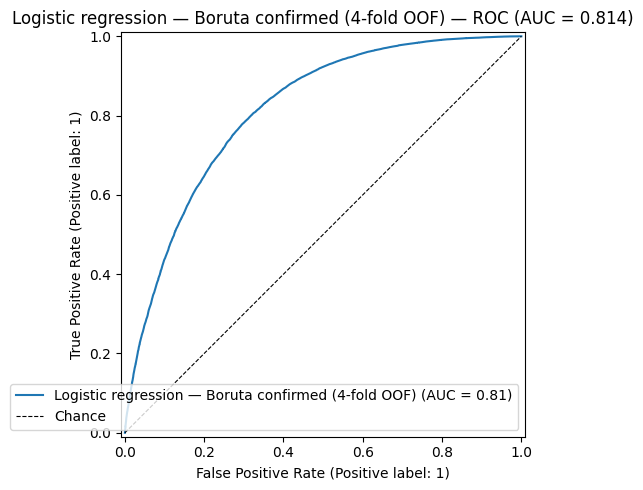

Confusion matrix (rows = true, columns = predicted):
[[25431  9915]
 [ 8463 26883]]


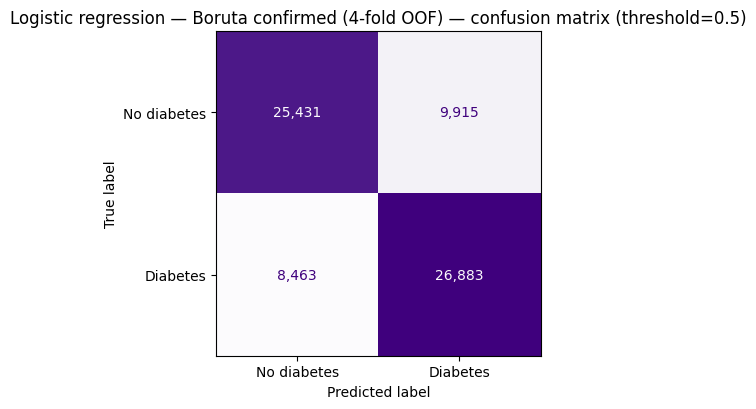

,value
accuracy,0.7400
balanced_accuracy,0.7400
precision,0.7306
recall,0.7606
f1,0.7453
roc_auc,0.8142


              precision    recall  f1-score   support

 No diabetes      0.750     0.719     0.735     35346
    Diabetes      0.731     0.761     0.745     35346

    accuracy                          0.740     70692
   macro avg      0.740     0.740     0.740     70692
weighted avg      0.740     0.740     0.740     70692


Coefficients — full-sample refit, target=diabetes_outcome, predictors=4 (Boruta confirmed)
Intercept: -4.0028


,feature,coefficient,odds_ratio
3,high_bp,0.8640,2.3726
1,gen_hlth,0.6554,1.9259
0,bmi,0.5863,1.7973
2,age,0.1878,1.2065


In [12]:
# Cell 20 · Logistic regression — Boruta confirmed features only
from IPython.display import display
from sklearn.linear_model import LogisticRegression

if "boruta_importance" not in globals():
    raise NameError("Run Cells 13–14 (Boruta) first.")
if "X" not in globals() or "y" not in globals() or "dm_run_cv" not in globals():
    raise NameError("Run Cell 16 first.")

BORUTA_CONFIRMED_PREDICTOR_COLS = (
    boruta_importance.loc[boruta_importance["decision"] == "confirmed"]
    .sort_values(["hit_rate", "mean_importance"], ascending=False)
    .index.tolist()
)
BORUTA_CONFIRMED_PREDICTOR_COLS = [
    c for c in BORUTA_CONFIRMED_PREDICTOR_COLS if c in MODELING_PREDICTOR_COLS
]
if not BORUTA_CONFIRMED_PREDICTOR_COLS:
    raise ValueError("No Boruta-confirmed features in MODELING_PREDICTOR_COLS.")

print(
    f"Boruta confirmed predictors (p={len(BORUTA_CONFIRMED_PREDICTOR_COLS)}): "
    f"{BORUTA_CONFIRMED_PREDICTOR_COLS}"
)

X_boruta_confirmed = X[BORUTA_CONFIRMED_PREDICTOR_COLS].astype(float)

dm_logistic_boruta_base = LogisticRegression(max_iter=5000, solver="lbfgs")
(
    dm_logistic_boruta_cv_detail,
    dm_logistic_boruta_cv_summary,
    dm_logistic_boruta_oof_pred,
    dm_logistic_boruta_oof_prob,
) = dm_run_cv(
    dm_logistic_boruta_base,
    X_boruta_confirmed,
    y,
    dm_skf,
    DM_MINORITY_CLASS_WEIGHT_EMPHASIS,
    "Logistic regression (Boruta confirmed)",
)

print("\n=== Logistic regression (Boruta confirmed) — out-of-fold evaluation ===")
dm_logistic_boruta_test_metrics = _dm_binary_classification_eval(
    y,
    dm_logistic_boruta_oof_pred,
    dm_logistic_boruta_oof_prob,
    DIABETES_CLASS_NAMES,
    f"Logistic regression — Boruta confirmed ({DM_CV_FOLDS}-fold OOF)",
    cm_cmap="Purples",
)
dm_logistic_boruta_test_metrics.name = "logistic_boruta_confirmed"

dm_logistic_boruta_model = LogisticRegression(
    max_iter=5000,
    solver="lbfgs",
    class_weight=dm_class_weight_dict(y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS),
)
dm_logistic_boruta_model.fit(X_boruta_confirmed, y)

dm_logistic_boruta_coef_table = pd.DataFrame(
    {
        "feature": BORUTA_CONFIRMED_PREDICTOR_COLS,
        "coefficient": dm_logistic_boruta_model.coef_.ravel(),
    }
)
dm_logistic_boruta_coef_table["odds_ratio"] = np.exp(
    dm_logistic_boruta_coef_table["coefficient"]
)

print(
    f"\nCoefficients — full-sample refit, target={DIABETES_OUTCOME_COL}, "
    f"predictors={len(BORUTA_CONFIRMED_PREDICTOR_COLS)} (Boruta confirmed)"
)
print(f"Intercept: {float(dm_logistic_boruta_model.intercept_[0]):.4f}")
display(
    dm_logistic_boruta_coef_table.sort_values(
        "coefficient", key=lambda s: s.abs(), ascending=False
    )
)


In [13]:
# Cell 21 · Compare all-feature vs Boruta-confirmed logistic vs RF
import numpy as np
from IPython.display import display

if "dm_logistic_aic" not in globals():
    if "dm_class_weight_dict" not in globals():
        raise NameError("Run Cell 16 first.")

    def dm_logistic_aic(model, X_df, y_s, emphasis=1.0):
        cw = dm_class_weight_dict(y_s, emphasis)
        y_arr = np.asarray(y_s, dtype=int)
        sw = np.where(y_arr == 1, cw[1], cw[0])
        p1 = np.clip(model.predict_proba(X_df)[:, 1], 1e-15, 1 - 1e-15)
        ll_i = y_arr * np.log(p1) + (1 - y_arr) * np.log(1 - p1)
        log_lik = float((sw * ll_i).sum())
        k = int(model.coef_.size + 1)
        return float(2 * k - 2 * log_lik)

required = (
    "dm_logistic_cv_summary",
    "dm_rf_cv_summary",
    "dm_logistic_boruta_cv_summary",
    "BORUTA_CONFIRMED_PREDICTOR_COLS",
)
missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(f"Run Cells 16, 17, and 20 first. Missing: {missing}")

metric_index = dm_logistic_cv_summary.index

dm_three_model_comparison = pd.DataFrame(
    {
        "logistic_all_features": dm_logistic_cv_summary["mean"],
        "random_forest_all_features": dm_rf_cv_summary["mean"],
        "logistic_boruta_confirmed": dm_logistic_boruta_cv_summary["mean"],
    },
    index=metric_index,
)
dm_three_model_comparison["delta_boruta_logistic_minus_all"] = (
    dm_three_model_comparison["logistic_boruta_confirmed"]
    - dm_three_model_comparison["logistic_all_features"]
)
dm_three_model_comparison["delta_rf_minus_all_logistic"] = (
    dm_three_model_comparison["random_forest_all_features"]
    - dm_three_model_comparison["logistic_all_features"]
)

if "dm_logistic_model" not in globals() or "dm_logistic_boruta_model" not in globals():
    raise NameError("Run Cells 16 and 20 first (full-sample models for AIC).")
dm_three_model_comparison.loc["aic"] = {
    "logistic_all_features": dm_logistic_aic(
        dm_logistic_model, X, y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS
    ),
    "random_forest_all_features": np.nan,
    "logistic_boruta_confirmed": dm_logistic_aic(
        dm_logistic_boruta_model,
        X_boruta_confirmed,
        y,
        DM_MINORITY_CLASS_WEIGHT_EMPHASIS,
    ),
}

print(
    f"CV comparison — {DM_CV_FOLDS} folds, n={len(y):,}, "
    f"all-features p={len(MODELING_PREDICTOR_COLS)}, "
    f"Boruta confirmed p={len(BORUTA_CONFIRMED_PREDICTOR_COLS)}, "
    f"minority emphasis={DM_MINORITY_CLASS_WEIGHT_EMPHASIS}, "
    f"random_state={DM_MODEL_RANDOM_STATE}"
)
display(dm_three_model_comparison.round(4))
print(
    "AIC row: full-sample logistic refits, class-weighted likelihood "
    "(lower is better). Random forest: AIC not applicable."
)

print("\nPer-fold ROC AUC:")
display(
    pd.DataFrame(
        {
            "logistic_all": dm_logistic_cv_detail["roc_auc"],
            "random_forest_all": dm_rf_cv_detail["roc_auc"],
            "logistic_boruta_confirmed": dm_logistic_boruta_cv_detail["roc_auc"],
        }
    ).round(4)
)

auc_all = float(dm_logistic_cv_summary.loc["roc_auc", "mean"])
auc_rf = float(dm_rf_cv_summary.loc["roc_auc", "mean"])
auc_boruta = float(dm_logistic_boruta_cv_summary.loc["roc_auc", "mean"])
best = max(
    [
        ("logistic (all features)", auc_all),
        ("random forest (all features)", auc_rf),
        ("logistic (Boruta confirmed)", auc_boruta),
    ],
    key=lambda item: item[1],
)
print(
    f"Highest mean CV ROC AUC: {best[0]} ({best[1]:.4f}). "
    f"(all logistic={auc_all:.4f}, RF={auc_rf:.4f}, Boruta logistic={auc_boruta:.4f})"
)


CV comparison — 4 folds, n=70,692, all-features p=21, Boruta confirmed p=4, minority emphasis=1.0, random_state=42


,logistic_all_features,random_forest_all_features,logistic_boruta_confirmed,delta_boruta_logistic_minus_all,delta_rf_minus_all_logistic
accuracy,0.7492,0.7426,0.7400,-0.0092,-0.0066
balanced_accuracy,0.7492,0.7426,0.7400,-0.0092,-0.0066
precision,0.7384,0.7234,0.7306,-0.0078,-0.0149
recall,0.7719,0.7854,0.7606,-0.0113,0.0135
f1,0.7548,0.7531,0.7453,-0.0095,-0.0016
roc_auc,0.8263,0.8174,0.8142,-0.0121,-0.0089
aic,71997.6719,NaN,74137.9933,NaN,NaN


AIC row: full-sample logistic refits, class-weighted likelihood (lower is better). Random forest: AIC not applicable.

Per-fold ROC AUC:


,logistic_all,random_forest_all,logistic_boruta_confirmed
fold,,,
1,0.8281,0.8167,0.8149
2,0.8242,0.8181,0.8121
3,0.8258,0.8158,0.8151
4,0.8273,0.8192,0.8147


Highest mean CV ROC AUC: logistic (all features) (0.8263). (all logistic=0.8263, RF=0.8174, Boruta logistic=0.8142)


**Cell 22 · Natural-prevalence evaluation overview**

Models in Cells **16–17** are fit on the **50/50** UCI subsample (`class_weight` reflects that balance). Here we **do not retrain**: we score the same fitted **logistic** and **random forest** on the **full BRFSS binary file** (~**14%** diabetes), using the **5050-fitted** Yeo–Johnson + scalers (`dm_continuous_preprocessors`).

This shows how accuracy, confusion patterns, and ROC behave when **prevalence shifts** from balanced training to the real-world mix. The UCI files are separate draws; treat this as **distribution / prevalence stress-test**, not a guaranteed row-disjoint holdout.

Compare metrics below to **5050 out-of-fold** results from Cells **16–17**.


Natural-prevalence evaluation set: n=253,680, diabetes prevalence = 13.933%
Majority-class baseline (always predict no diabetes): accuracy = 86.067%
Training context (5050 subsample): n=70,692, prevalence = 50.000%

=== Logistic regression (5050-trained) — full cohort evaluation ===
Logistic (trained 50/50, tested natural prevalence) — ROC AUC: 0.8247


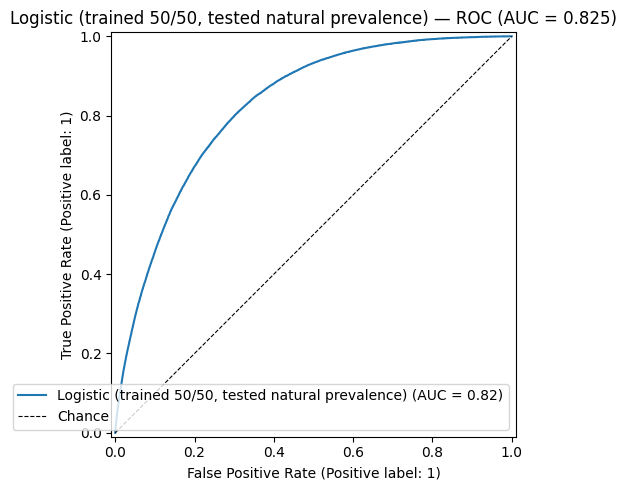

Confusion matrix (rows = true, columns = predicted):
[[158173  60161]
 [  8072  27274]]


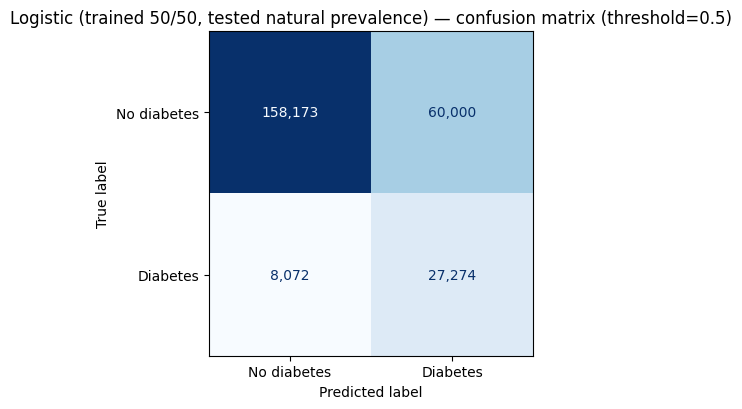

,value
accuracy,0.7310
balanced_accuracy,0.7480
precision,0.3119
recall,0.7716
f1,0.4443
roc_auc,0.8247


              precision    recall  f1-score   support

 No diabetes      0.951     0.724     0.823    218334
    Diabetes      0.312     0.772     0.444     35346

    accuracy                          0.731    253680
   macro avg      0.632     0.748     0.633    253680
weighted avg      0.862     0.731     0.770    253680


=== Random forest (5050-trained) — full cohort evaluation ===
Random forest (trained 50/50, tested natural prevalence) — ROC AUC: 0.9268


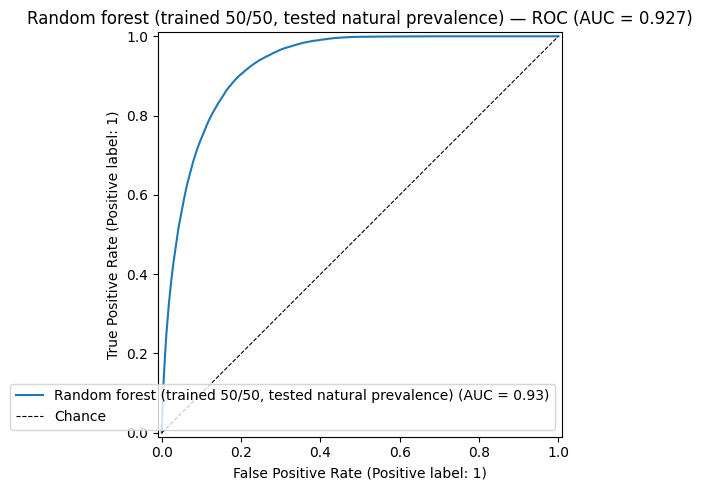

Confusion matrix (rows = true, columns = predicted):
[[160636  57698]
 [  1788  33558]]


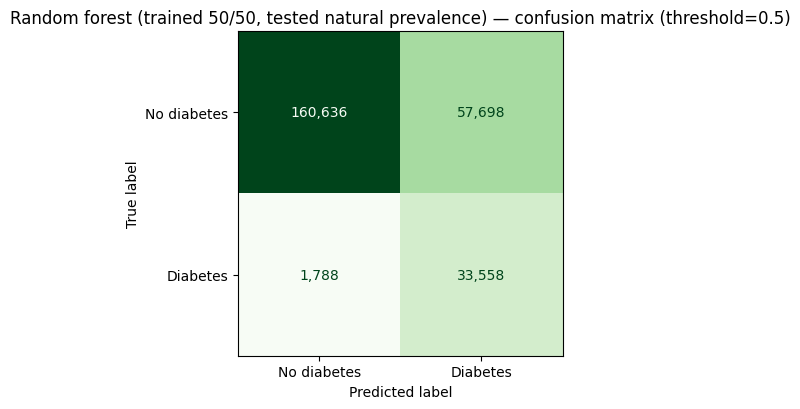

,value
accuracy,0.7655
balanced_accuracy,0.8426
precision,0.3677
recall,0.9494
f1,0.5301
roc_auc,0.9268


              precision    recall  f1-score   support

 No diabetes      0.989     0.736     0.844    218334
    Diabetes      0.368     0.949     0.530     35346

    accuracy                          0.766    253680
   macro avg      0.678     0.843     0.687    253680
weighted avg      0.902     0.766     0.800    253680


=== Metrics: 5050 OOF vs natural-prevalence full cohort ===


,logistic_5050_oof,rf_5050_oof,logistic_full_cohort,rf_full_cohort
accuracy,0.7492,0.7426,0.7310,0.7655
balanced_accuracy,0.7492,0.7426,0.7480,0.8426
precision,0.7384,0.7234,0.3119,0.3677
recall,0.7719,0.7854,0.7716,0.9494
f1,0.7548,0.7531,0.4443,0.5301
roc_auc,0.8263,0.8174,0.8247,0.9268



Note: OOF metrics are from 50/50 CV on the subsample; full-cohort columns use n=253,680 at ~13.9% diabetes prevalence.


In [14]:
# Cell 23 · Score 5050-trained models on full-cohort (imbalanced) data
from IPython.display import display

import numpy as np
import pandas as pd

required = (
    "dm_logistic_model",
    "dm_rf_model",
    "dm_continuous_preprocessors",
    "MODELING_PREDICTOR_COLS",
    "DIABETES_OUTCOME_COL",
    "COLUMN_RENAME",
    "DATA_DIR",
    "_dm_binary_classification_eval",
    "_dm_fold_metrics",
)
missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        "Run Cells 02, 10, 16, and 17 first. Missing: " + ", ".join(missing)
    )

FULL_DATA_FILE = DATA_DIR / "diabetes_binary_health_indicators_BRFSS2015.csv"
if not FULL_DATA_FILE.exists():
    raise FileNotFoundError(f"Full cohort CSV not found: {FULL_DATA_FILE.resolve()}")

df_nat_raw = pd.read_csv(FULL_DATA_FILE).rename(columns=COLUMN_RENAME)
for col in df_nat_raw.columns:
    df_nat_raw[col] = pd.to_numeric(df_nat_raw[col], errors="coerce")
n_before = len(df_nat_raw)
df_nat_raw = df_nat_raw.dropna(how="any")
if len(df_nat_raw) < n_before:
    print(f"Dropped {n_before - len(df_nat_raw):,} rows with missing values (full file)")

predictor_cols = [c for c in df_nat_raw.columns if c != "diabetes_binary"]
df_nat_model = df_nat_raw[predictor_cols].copy()
df_nat_model[DIABETES_OUTCOME_COL] = df_nat_raw["diabetes_binary"].astype(int)

missing_preds = [c for c in MODELING_PREDICTOR_COLS if c not in df_nat_model.columns]
if missing_preds:
    raise ValueError(f"Full cohort missing predictors: {missing_preds}")

df_nat_scaled = df_nat_model.copy()
for col, pipe in dm_continuous_preprocessors.items():
    df_nat_scaled[col] = pipe.transform(
        df_nat_model[[col]].astype(float)
    ).ravel()

X_nat = df_nat_scaled[MODELING_PREDICTOR_COLS].astype(float)
y_nat = df_nat_scaled[DIABETES_OUTCOME_COL].astype(int)
if X_nat.isna().any().any():
    raise ValueError("NaN in natural-prevalence feature matrix after transform.")

nat_prev = float(y_nat.mean())
majority_acc = float((y_nat == 0).mean())
print(
    f"Natural-prevalence evaluation set: n={len(y_nat):,}, "
    f"diabetes prevalence = {nat_prev:.3%}"
)
print(
    f"Majority-class baseline (always predict no diabetes): accuracy = {majority_acc:.3%}"
)
print(
    f"Training context (5050 subsample): n={len(y):,}, prevalence = {float(y.mean()):.3%}"
)

log_prob = dm_logistic_model.predict_proba(X_nat)[:, 1]
log_pred = dm_logistic_model.predict(X_nat)
rf_prob = dm_rf_model.predict_proba(X_nat)[:, 1]
rf_pred = dm_rf_model.predict(X_nat)

print("\n=== Logistic regression (5050-trained) — full cohort evaluation ===")
dm_logistic_nat_metrics = _dm_binary_classification_eval(
    y_nat,
    log_pred,
    log_prob,
    DIABETES_CLASS_NAMES,
    "Logistic (trained 50/50, tested natural prevalence)",
    cm_cmap="Blues",
)
dm_logistic_nat_metrics.name = "logistic_natural_prevalence"

print("\n=== Random forest (5050-trained) — full cohort evaluation ===")
dm_rf_nat_metrics = _dm_binary_classification_eval(
    y_nat,
    rf_pred,
    rf_prob,
    DIABETES_CLASS_NAMES,
    "Random forest (trained 50/50, tested natural prevalence)",
    cm_cmap="Greens",
)
dm_rf_nat_metrics.name = "random_forest_natural_prevalence"

def _metrics_series_if_present(name: str) -> pd.Series | None:
    if name not in globals():
        return None
    obj = globals()[name]
    if isinstance(obj, pd.Series):
        return obj
    return None

rows = ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc"]
dm_prevalence_shift_comparison = pd.DataFrame(index=rows)

if _metrics_series_if_present("dm_logistic_test_metrics") is not None:
    dm_prevalence_shift_comparison["logistic_5050_oof"] = dm_logistic_test_metrics.reindex(
        rows
    )
if _metrics_series_if_present("dm_rf_test_metrics") is not None:
    dm_prevalence_shift_comparison["rf_5050_oof"] = dm_rf_test_metrics.reindex(rows)

dm_prevalence_shift_comparison["logistic_full_cohort"] = dm_logistic_nat_metrics.reindex(
    rows
)
dm_prevalence_shift_comparison["rf_full_cohort"] = dm_rf_nat_metrics.reindex(rows)

print("\n=== Metrics: 5050 OOF vs natural-prevalence full cohort ===")
display(dm_prevalence_shift_comparison.round(4))

print(
    "\nNote: OOF metrics are from 50/50 CV on the subsample; full-cohort columns use "
    f"n={len(y_nat):,} at ~{nat_prev:.1%} diabetes prevalence."
)

log_prob_nat = log_prob
rf_prob_nat = rf_prob
y_nat_test = y_nat


**Cell 24 · Threshold sweep overview (natural prevalence)**

Cell **23** scored **5050-trained** logistic and RF models on the **full BRFSS** (~14% diabetes) at the default **0.5** threshold. Here we **sweep decision thresholds** on the same predicted probabilities and trace **precision vs recall**.

For screening-style use, missing diabetes (**false negatives**) is often costlier than flagging healthy people (**false positives**). That means **lower thresholds** → **higher recall**, usually **lower precision**. Use the tables and plots below to pick an operating point (e.g. target recall with acceptable precision).


Threshold sweep on natural-prevalence cohort: n=253,680, diabetes prevalence = 13.933%
Grid: 0.05 … 0.95 (step 0.05)

Logistic (5050-trained) — average precision (PR AUC): 0.4153
Random forest (5050-trained) — average precision (PR AUC): 0.6510


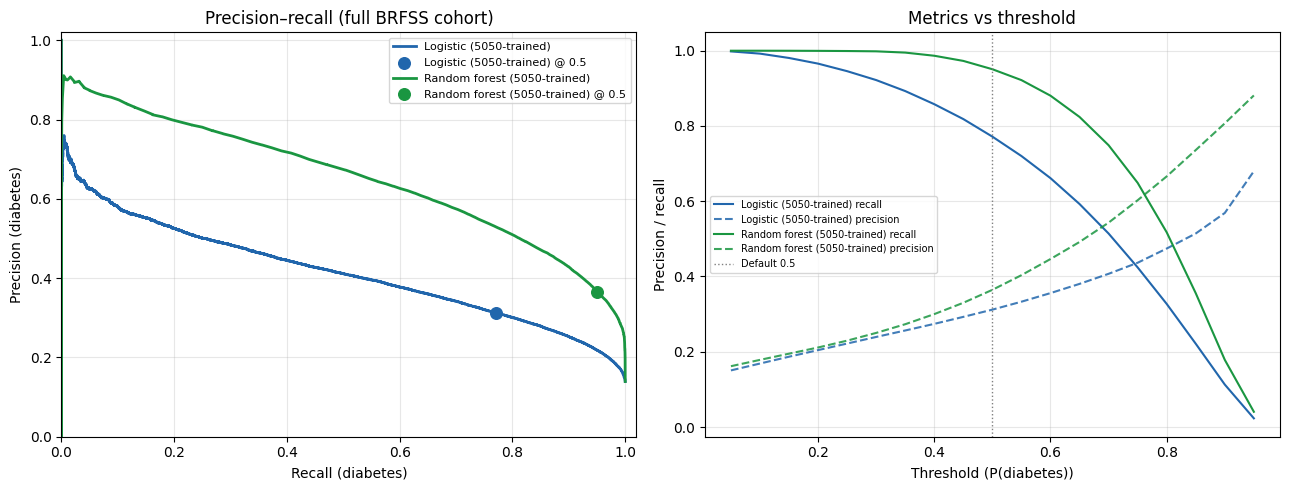

=== Threshold grid (selected columns) ===


,model,threshold,precision,recall,f1,fp,fn,predicted_positive_rate
0,Logistic (5050-trained),0.0500,0.1505,0.9982,0.2615,199209,65,0.9244
1,Logistic (5050-trained),0.1000,0.1687,0.9922,0.2884,172808,274,0.8195
2,Logistic (5050-trained),0.1500,0.1868,0.9807,0.3139,150858,682,0.7313
3,Logistic (5050-trained),0.2000,0.2044,0.9657,0.3374,132862,1213,0.6583
4,Logistic (5050-trained),0.2500,0.2218,0.9456,0.3593,117256,1922,0.5940
5,Logistic (5050-trained),0.3000,0.2393,0.9220,0.3800,103567,2758,0.5367
6,Logistic (5050-trained),0.3500,0.2565,0.8927,0.3986,91445,3791,0.4849
7,Logistic (5050-trained),0.4000,0.2741,0.8579,0.4155,80294,5024,0.4360
8,Logistic (5050-trained),0.4500,0.2927,0.8183,0.4312,69886,6422,0.3895
9,Logistic (5050-trained),0.5000,0.3119,0.7716,0.4443,60161,8072,0.3447



=== Screening-oriented picks: highest threshold with recall ≥ target ===
(Recall floor with best precision on this grid; lower targets allow stricter cutoffs.)



,model,target_recall>=,threshold,precision,recall,f1,fp,fn
0,Logistic (5050-trained),0.7500,0.5000,0.3119,0.7716,0.4443,60161,8072
1,Logistic (5050-trained),0.8000,0.4500,0.2927,0.8183,0.4312,69886,6422
2,Logistic (5050-trained),0.8500,0.4000,0.2741,0.8579,0.4155,80294,5024
3,Logistic (5050-trained),0.9000,0.3000,0.2393,0.9220,0.3800,103567,2758
4,Logistic (5050-trained),0.9500,0.2000,0.2044,0.9657,0.3374,132862,1213
5,Random forest (5050-trained),0.7500,0.6500,0.4918,0.8240,0.6159,30101,6222
6,Random forest (5050-trained),0.8000,0.6500,0.4918,0.8240,0.6159,30101,6222
7,Random forest (5050-trained),0.8500,0.6000,0.4464,0.8805,0.5925,38591,4225
8,Random forest (5050-trained),0.9000,0.5500,0.4035,0.9219,0.5613,48167,2762
9,Random forest (5050-trained),0.9500,0.5000,0.3645,0.9508,0.5270,58581,1739



=== Default threshold 0.5 (same as Cell 23 hard labels) ===


,model,precision,recall,f1,fp,fn,predicted_positive_rate
9,Logistic (5050-trained),0.3119,0.7716,0.4443,60161,8072,0.3447
28,Random forest (5050-trained),0.3645,0.9508,0.5270,58581,1739,0.3634


In [15]:
# Cell 25 · Precision–recall threshold sweep (full cohort)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_curve, average_precision_score

if "y_nat" not in globals() or "log_prob" not in globals() or "rf_prob" not in globals():
    raise NameError("Run Cell 23 first (natural-prevalence scoring).")

THRESHOLD_GRID = np.round(np.arange(0.05, 0.96, 0.05), 2)
TARGET_RECALLS = (0.75, 0.80, 0.85, 0.90, 0.95)


def dm_threshold_metrics(y_true, y_prob, threshold: float) -> dict[str, float]:
    y_pred = (y_prob >= threshold).astype(int)
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall)
        else 0.0
    )
    return {
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "predicted_positive_rate": float(y_pred.mean()),
    }


def dm_threshold_sweep_table(
    y_true, y_prob, model_name: str, thresholds: np.ndarray
) -> pd.DataFrame:
    rows = [dm_threshold_metrics(y_true, y_prob, float(t)) for t in thresholds]
    return pd.DataFrame(rows).assign(model=model_name)


def dm_threshold_for_min_recall(
    y_true, y_prob, min_recall: float, thresholds: np.ndarray
) -> pd.Series:
    # Highest threshold on grid with recall >= min_recall (best precision at that floor).
    table = dm_threshold_sweep_table(y_true, y_prob, "", thresholds)
    ok = table[table["recall"] >= min_recall]
    if ok.empty:
        return pd.Series({"threshold": np.nan, "precision": np.nan, "recall": np.nan, "f1": np.nan})
    best = ok.sort_values(["threshold", "precision"], ascending=[False, False]).iloc[0]
    return best


y_eval = np.asarray(y_nat, dtype=int)
models = {
    "Logistic (5050-trained)": np.asarray(log_prob, dtype=float),
    "Random forest (5050-trained)": np.asarray(rf_prob, dtype=float),
}

sweep_tables = [
    dm_threshold_sweep_table(y_eval, prob, name, THRESHOLD_GRID)
    for name, prob in models.items()
]
dm_threshold_sweep = pd.concat(sweep_tables, ignore_index=True)

print(
    f"Threshold sweep on natural-prevalence cohort: n={len(y_eval):,}, "
    f"diabetes prevalence = {y_eval.mean():.3%}"
)
print(f"Grid: {THRESHOLD_GRID[0]:.2f} … {THRESHOLD_GRID[-1]:.2f} (step 0.05)\n")

for name, prob in models.items():
    ap = average_precision_score(y_eval, prob)
    print(f"{name} — average precision (PR AUC): {ap:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {"Logistic (5050-trained)": "#2166ac", "Random forest (5050-trained)": "#1a9641"}

for name, prob in models.items():
    prec, rec, _ = precision_recall_curve(y_eval, prob)
    axes[0].plot(rec, prec, label=f"{name}", color=colors[name], lw=2)
    axes[0].scatter(
        [dm_threshold_metrics(y_eval, prob, 0.5)["recall"]],
        [dm_threshold_metrics(y_eval, prob, 0.5)["precision"]],
        color=colors[name],
        s=70,
        marker="o",
        zorder=5,
        label=f"{name} @ 0.5",
    )

axes[0].set_xlabel("Recall (diabetes)")
axes[0].set_ylabel("Precision (diabetes)")
axes[0].set_title("Precision–recall (full BRFSS cohort)")
axes[0].set_xlim(0, 1.02)
axes[0].set_ylim(0, 1.02)
axes[0].legend(loc="best", fontsize=8)
axes[0].grid(True, alpha=0.3)

for name, prob in models.items():
    sub = dm_threshold_sweep[dm_threshold_sweep["model"] == name]
    axes[1].plot(sub["threshold"], sub["recall"], label=f"{name} recall", color=colors[name])
    axes[1].plot(
        sub["threshold"],
        sub["precision"],
        label=f"{name} precision",
        color=colors[name],
        linestyle="--",
        alpha=0.85,
    )

axes[1].axvline(0.5, color="gray", linestyle=":", lw=1, label="Default 0.5")
axes[1].set_xlabel("Threshold (P(diabetes))")
axes[1].set_ylabel("Precision / recall")
axes[1].set_title("Metrics vs threshold")
axes[1].legend(loc="best", fontsize=7)
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print("=== Threshold grid (selected columns) ===")
display(
    dm_threshold_sweep[
        ["model", "threshold", "precision", "recall", "f1", "fp", "fn", "predicted_positive_rate"]
    ].round(4)
)

target_rows = []
for name, prob in models.items():
    for target in TARGET_RECALLS:
        row = dm_threshold_for_min_recall(y_eval, prob, target, THRESHOLD_GRID)
        target_rows.append(
            {
                "model": name,
                "target_recall>=": target,
                "threshold": row["threshold"],
                "precision": row["precision"],
                "recall": row["recall"],
                "f1": row["f1"],
                "fp": row.get("fp", np.nan),
                "fn": row.get("fn", np.nan),
            }
        )

dm_threshold_by_recall_target = pd.DataFrame(target_rows)
print(
    "\n=== Screening-oriented picks: highest threshold with recall ≥ target ==="
)
print("(Recall floor with best precision on this grid; lower targets allow stricter cutoffs.)\n")
display(dm_threshold_by_recall_target.round(4))

baseline = dm_threshold_sweep[dm_threshold_sweep["threshold"] == 0.5]
if len(baseline):
    print("\n=== Default threshold 0.5 (same as Cell 23 hard labels) ===")
    display(
        baseline[
            ["model", "precision", "recall", "f1", "fp", "fn", "predicted_positive_rate"]
        ].round(4)
    )


**Cell 26 · Fixed threshold 0.65 overview**

On the **natural-prevalence** full cohort (Cell **23**), apply decision threshold **0.65** to both **5050-trained** models. **ROC** curves are threshold-free; **confusion matrices** use **P(diabetes) ≥ 0.65**. Summary metrics are in a side-by-side comparison table.


Full-cohort evaluation @ threshold = 0.65 (n=253,680, diabetes prevalence = 13.933%)


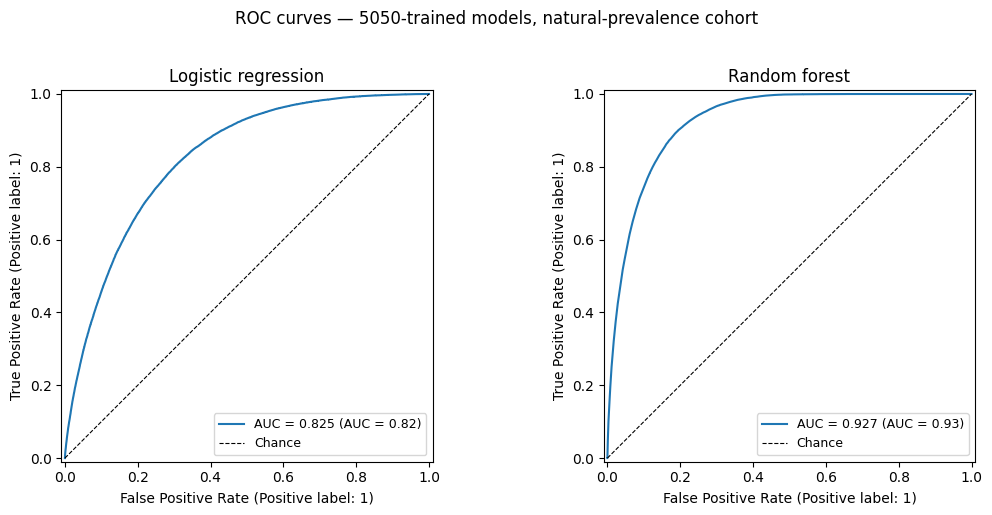

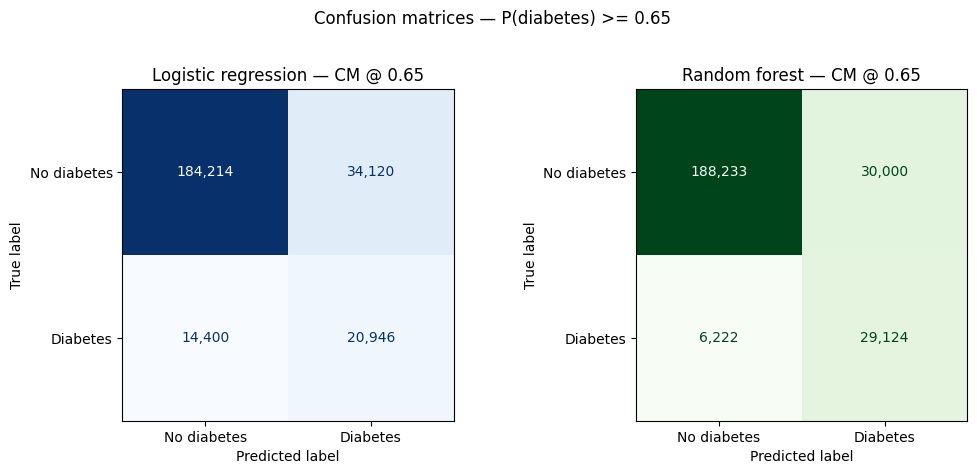


=== Model comparison @ threshold 0.65 (full cohort) ===


,logistic_regression,random_forest,delta_rf_minus_logistic
accuracy,0.8087,0.8568,0.0481
balanced_accuracy,0.7182,0.8431,0.1249
precision,0.3804,0.4918,0.1114
recall,0.5926,0.8240,0.2314
f1,0.4633,0.6159,0.1526
roc_auc,0.8247,0.9268,0.1022
predicted_positive_rate,0.2171,0.2335,0.0164
tp,184214.0000,188233.0000,4019.0000
fp,34120.0000,30101.0000,-4019.0000
fn,14400.0000,6222.0000,-8178.0000



=== Context: default threshold 0.5 (from Cell 23) vs 0.65 ===


,logistic@0.5,logistic@0.65,rf@0.5,rf@0.65
precision,0.3119,0.3804,0.3677,0.4918
recall,0.7716,0.5926,0.9494,0.8240
f1,0.4443,0.4633,0.5301,0.6159
accuracy,0.7310,0.8087,0.7655,0.8568
balanced_accuracy,0.7480,0.7182,0.8426,0.8431


In [16]:
# Cell 27 · Threshold 0.65 — ROC, confusion matrices, comparison
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    confusion_matrix,
    roc_auc_score,
)

DECISION_THRESHOLD = 0.65

if "y_nat" not in globals() or "log_prob" not in globals() or "rf_prob" not in globals():
    raise NameError("Run Cell 23 first (natural-prevalence scoring).")
if "_dm_fold_metrics" not in globals():
    raise NameError("Run Cell 16 first (loads _dm_fold_metrics).")

y_eval = np.asarray(y_nat, dtype=int)
model_specs = [
    ("Logistic regression", np.asarray(log_prob, dtype=float), "Blues"),
    ("Random forest", np.asarray(rf_prob, dtype=float), "Greens"),
]

print(
    f"Full-cohort evaluation @ threshold = {DECISION_THRESHOLD:.2f} "
    f"(n={len(y_eval):,}, diabetes prevalence = {y_eval.mean():.3%})"
)

fig_roc, axes_roc = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, prob, _) in zip(axes_roc, model_specs):
    auc = roc_auc_score(y_eval, prob)
    RocCurveDisplay.from_predictions(
        y_eval,
        prob,
        ax=ax,
        name=f"AUC = {auc:.3f}",
    )
    ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Chance")
    ax.set_title(f"{name}")
    ax.legend(loc="lower right", fontsize=9)
fig_roc.suptitle(
    "ROC curves — 5050-trained models, natural-prevalence cohort",
    y=1.02,
    fontsize=12,
)
fig_roc.tight_layout()
plt.show()

fig_cm, axes_cm = plt.subplots(1, 2, figsize=(10.5, 4.6))
metric_rows: list[dict] = []

for ax, (name, prob, cmap) in zip(axes_cm, model_specs):
    y_pred = (prob >= DECISION_THRESHOLD).astype(int)
    cm = confusion_matrix(y_eval, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=DIABETES_CLASS_NAMES,
    ).plot(ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(f"{name} — CM @ {DECISION_THRESHOLD:.2f}")
    m = _dm_fold_metrics(y_eval, y_pred, prob)
    m["model"] = name
    m["threshold"] = DECISION_THRESHOLD
    m["predicted_positive_rate"] = float(y_pred.mean())
    m["roc_auc"] = roc_auc_score(y_eval, prob)
    tp, fp, fn, tn = cm.ravel()
    m["tp"], m["fp"], m["fn"], m["tn"] = int(tp), int(fp), int(fn), int(tn)
    metric_rows.append(m)

fig_cm.suptitle(
    f"Confusion matrices — P(diabetes) >= {DECISION_THRESHOLD:.2f}",
    y=1.02,
    fontsize=12,
)
fig_cm.tight_layout()
plt.show()

metrics_df = pd.DataFrame(metric_rows).set_index("model")
compare_cols = [
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "predicted_positive_rate",
    "tp",
    "fp",
    "fn",
    "tn",
]

dm_nat_threshold_065_comparison = pd.DataFrame(
    {
        "logistic_regression": metrics_df.loc["Logistic regression", compare_cols],
        "random_forest": metrics_df.loc["Random forest", compare_cols],
    }
)
dm_nat_threshold_065_comparison["delta_rf_minus_logistic"] = (
    dm_nat_threshold_065_comparison["random_forest"]
    - dm_nat_threshold_065_comparison["logistic_regression"]
)

print(f"\n=== Model comparison @ threshold {DECISION_THRESHOLD:.2f} (full cohort) ===")
display(dm_nat_threshold_065_comparison.round(4))

if "dm_prevalence_shift_comparison" in globals():
    print("\n=== Context: default threshold 0.5 (from Cell 23) vs 0.65 ===")
    ctx_rows = ["precision", "recall", "f1", "accuracy", "balanced_accuracy"]
    ctx = pd.DataFrame(index=ctx_rows)
    if "logistic_full_cohort" in dm_prevalence_shift_comparison.columns:
        ctx["logistic@0.5"] = dm_prevalence_shift_comparison.loc[
            ctx_rows, "logistic_full_cohort"
        ]
    ctx["logistic@0.65"] = dm_nat_threshold_065_comparison.loc[
        ctx_rows, "logistic_regression"
    ]
    if "rf_full_cohort" in dm_prevalence_shift_comparison.columns:
        ctx["rf@0.5"] = dm_prevalence_shift_comparison.loc[ctx_rows, "rf_full_cohort"]
    ctx["rf@0.65"] = dm_nat_threshold_065_comparison.loc[ctx_rows, "random_forest"]
    display(ctx.round(4))
